# Exploratory Data Analysis — Corporate Environmental Impact

This notebook presents a comprehensive EDA of corporate environmental impact, covering both descriptive patterns and comparisons across industries, countries, and years.

## EDA structure

1. **Overall distribution**
   - Environmental intensity relative to sales
   - Total environmental cost
2. **Impact composition**
   - Safeguard contributions
3. **Outliers & concentration**
   - Extreme environmental intensity
   - Pareto / concentration of environmental cost
4. **Variable relationships and data reliability**
   - Correlation
   - Sensitivity to `% imputed`
5. **Cross-sectional and temporal differences**
   - Industry differences
   - Country differences
   - Full-sample and balanced-panel temporal patterns

> **Primary outcome:** `environmental_intensity_sales`  
> More negative values indicate a larger environmental cost relative to sales, while values closer to zero indicate lower environmental cost intensity.


## 0. Setup

The cleaned dataset should be placed in the same folder as this notebook and named:

`cleaned_environmental_impact_data.xlsx`

The code also includes a fallback path for the current ChatGPT working environment.


In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import textwrap
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

# ---- Environmental research color theme ----
COLORS = {
    "forest": "#145A43",
    "green": "#218C74",
    "sage": "#80B8A1",
    "mint": "#CAE7DA",
    "teal": "#187F86",
    "navy": "#17334A",
    "gray": "#667781",
    "grid": "#E5EFEB",
    "background": "#FFFFFF",
}

plt.rcParams.update({
    "figure.facecolor": COLORS["background"],
    "axes.facecolor": COLORS["background"],
    "axes.edgecolor": "#DCE6E0",
    "axes.labelcolor": COLORS["navy"],
    "text.color": COLORS["navy"],
    "xtick.color": COLORS["gray"],
    "ytick.color": COLORS["gray"],
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "font.size": 11,
    "savefig.dpi": 300,
    "axes.prop_cycle": cycler(color=[COLORS["forest"], COLORS["green"], COLORS["sage"], COLORS["teal"], COLORS["navy"]]),
    "grid.color": COLORS["grid"],
    "grid.linewidth": 0.8,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print("Environmental research theme ready!")

# ---- Load cleaned data ----
candidate_paths = [
    Path("cleaned_environmental_impact_data.xlsx"),
    Path("/mnt/data/cleaned_environmental_impact_data.xlsx"),
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find cleaned_environmental_impact_data.xlsx. "
        "Place the file in the same folder as this notebook."
    )

df = pd.read_excel(DATA_PATH)

print(f"Loaded: {DATA_PATH}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")

# Columns used in this EDA
INTENSITY = "environmental_intensity_sales"
TOTAL_COST = "total_environmental_cost"
IMPUTED = "pct_imputed"

SAFEGUARD_COLS = [
    "working_capacity",
    "fish_production_capacity",
    "crop_production_capacity",
    "meat_production_capacity",
    "biodiversity",
    "abiotic_resources",
    "water_production_capacity_drinking_water_and_irrigation_water",
    "wood_production_capacity",
]

required_cols = [INTENSITY, TOTAL_COST, IMPUTED, "company_name"] + SAFEGUARD_COLS
missing_required = [c for c in required_cols if c not in df.columns]

if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")

print("All required EDA columns are available.")


/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-pgrwiuks because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Environmental research theme ready!


Loaded: cleaned_environmental_impact_data.xlsx
Shape: 14,015 rows × 34 columns
All required EDA columns are available.


# 1. Overall distribution

This section examines the unconditional distribution of the two main environmental-impact measures across the **entire cleaned sample**.

The goal is to establish:

- center and spread;
- skewness and tail behavior;
- whether most observations are negative, zero, or positive;
- whether extreme values materially affect the visual distribution.

No industry, country, or year grouping is used here.


In [2]:
def extended_descriptives(series, name):
    s = series.dropna()
    q = s.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])

    return pd.Series({
        "Variable": name,
        "N": len(s),
        "Mean": s.mean(),
        "Median": s.median(),
        "Std. Dev.": s.std(),
        "Skewness": s.skew(),
        "Kurtosis": s.kurt(),
        "Min": s.min(),
        "P1": q.loc[0.01],
        "P5": q.loc[0.05],
        "P25": q.loc[0.25],
        "P50": q.loc[0.50],
        "P75": q.loc[0.75],
        "P95": q.loc[0.95],
        "P99": q.loc[0.99],
        "Max": s.max(),
    })

distribution_summary = pd.DataFrame([
    extended_descriptives(df[INTENSITY], "Environmental intensity / sales"),
    extended_descriptives(df[TOTAL_COST], "Total environmental cost"),
]).set_index("Variable")

display(distribution_summary)


,N,Mean,Median,Std. Dev.,Skewness,Kurtosis,Min,P1,P5,P25,P50,P75,P95,P99,Max
Variable,,,,,,,,,,,,,,,
Environmental intensity / sales,14015,-0.111229,-0.020217,0.268402,-3.293724,16.041576,-1.992787,-1.434013,-0.618618,-0.090633,-0.020217,-0.006860,-0.001034,0.102486,1.903596
Total environmental cost,14015,"-1,129,931,591.837977","-93,407,858.967558","4,901,090,559.728010",-8.597235,111.892620,"-114,442,352,167.862595","-19,787,413,276.223843","-5,272,693,764.550178","-442,158,744.463749","-93,407,858.967558","-20,429,087.390826","-1,058,040.014450","425,151,354.316747","52,111,018,150.987747"


In [3]:
# Sign structure of the two key measures
def sign_summary(series):
    s = series.dropna()
    n = len(s)
    return pd.Series({
        "Negative N": (s < 0).sum(),
        "Negative %": (s < 0).mean() * 100,
        "Zero N": (s == 0).sum(),
        "Zero %": (s == 0).mean() * 100,
        "Positive N": (s > 0).sum(),
        "Positive %": (s > 0).mean() * 100,
    })

sign_table = pd.DataFrame({
    "Environmental intensity / sales": sign_summary(df[INTENSITY]),
    "Total environmental cost": sign_summary(df[TOTAL_COST]),
}).T

display(sign_table)


,Negative N,Negative %,Zero N,Zero %,Positive N,Positive %
Environmental intensity / sales,"13,667.000000",97.516946,0.000000,0.000000,348.000000,2.483054
Total environmental cost,"13,667.000000",97.516946,0.000000,0.000000,348.000000,2.483054


### 1.1 Environmental intensity relative to sales

Because environmental intensity can contain a long tail, three complementary views are shown:

1. the full distribution;
2. a P1–P99 trimmed view for better visibility of the central mass;
3. a **log-magnitude view for negative observations only**, using `log10(|intensity|)`.

The trimming and log transformation are **for visualization only**. No observations are deleted or replaced in the dataset.

> The log-magnitude plot is restricted to negative intensity values because these represent environmental costs in the primary outcome. Positive observations remain visible in the full and P1–P99 plots.


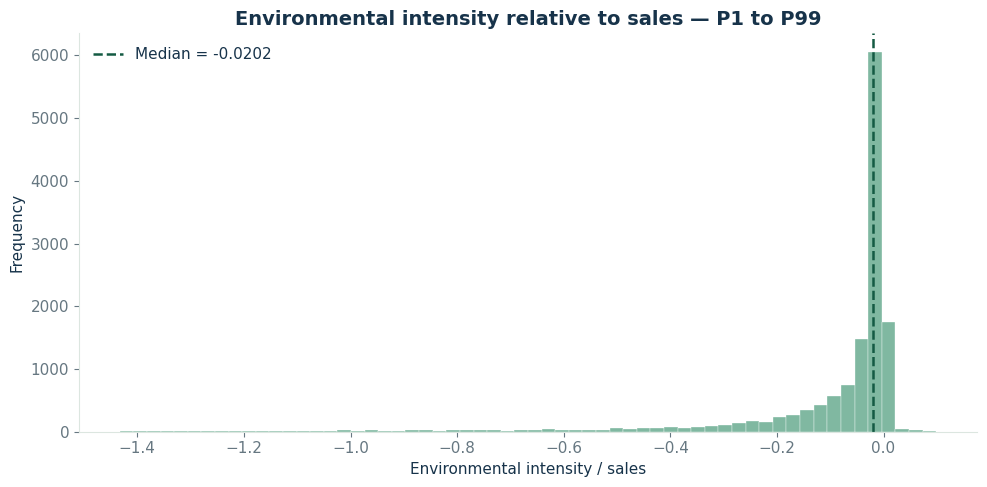

In [4]:
# P1-P99 view for environmental intensity; full distribution and boxplot are in the combined panel below.
s = df[INTENSITY].dropna()
p1, p99 = s.quantile([0.01, 0.99])
trimmed = s[(s >= p1) & (s <= p99)]

plt.figure(figsize=(10, 5))
plt.hist(trimmed, bins=60, color=COLORS["sage"], edgecolor=COLORS["background"], linewidth=0.25)
plt.axvline(
    trimmed.median(), color=COLORS["forest"], linestyle="--", linewidth=1.8,
    label=f"Median = {trimmed.median():.4f}"
)
plt.title("Environmental intensity relative to sales — P1 to P99")
plt.xlabel("Environmental intensity / sales")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

#### Log-magnitude view — negative environmental intensity

This view focuses on the negative observations and plots `log10(|environmental intensity|)`. It makes differences in magnitude easier to see when many values are packed close to zero on the original scale.


In [5]:
# The negative-intensity log-magnitude plot is included in the combined distribution panel below.
negative_intensity = df.loc[df[INTENSITY] < 0, INTENSITY].dropna()

print(
    f"Negative observations shown in the log-magnitude panel: {len(negative_intensity):,} "
    f"({len(negative_intensity) / df[INTENSITY].notna().sum() * 100:.2f}% of non-missing intensity observations)"
)

Negative observations shown in the log-magnitude panel: 13,667 (97.52% of non-missing intensity observations)


### 1.2 Total environmental cost

The same full-distribution and P1–P99 views are used for total environmental cost.

A third **signed-log view** is added because the raw values span a very wide range (the executed summary shows a minimum of about **−114.44 billion**). A normal logarithm cannot be applied directly because the variable contains both negative and positive values, so the visualization uses:

`sign(x) × log10(1 + |x|)`

This compresses extreme magnitudes while preserving whether the original cost is negative or positive. The transformation is **for visualization only**; all analysis continues to use the original values.


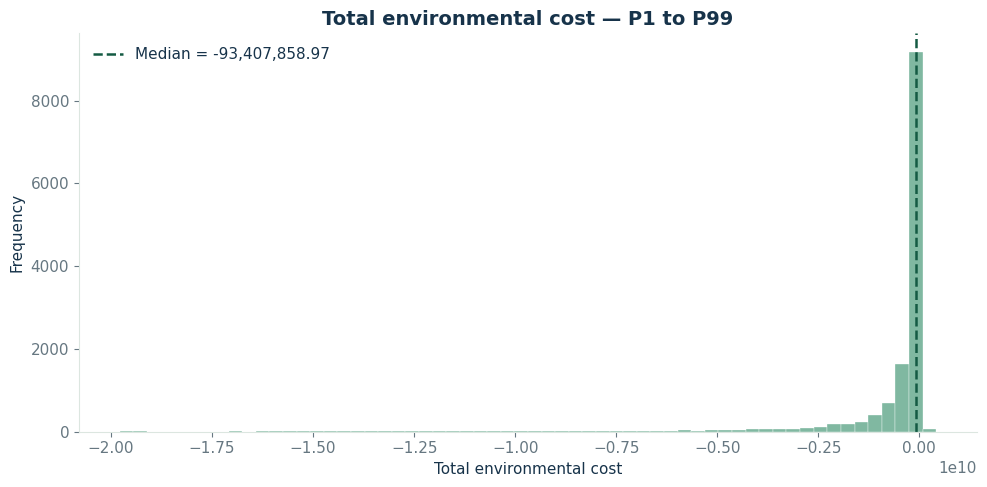

In [6]:
# P1-P99 view for total environmental cost; full distribution and boxplot are in the combined panel below.
s = df[TOTAL_COST].dropna()
p1, p99 = s.quantile([0.01, 0.99])
trimmed = s[(s >= p1) & (s <= p99)]

plt.figure(figsize=(10, 5))
plt.hist(trimmed, bins=60, color=COLORS["sage"], edgecolor=COLORS["background"], linewidth=0.25)
plt.axvline(
    trimmed.median(), color=COLORS["forest"], linestyle="--", linewidth=1.8,
    label=f"Median = {trimmed.median():,.2f}"
)
plt.title("Total environmental cost — P1 to P99")
plt.xlabel("Total environmental cost")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

#### Signed-log view — total environmental cost

Because total environmental cost contains both negative and positive observations, this plot uses a signed log transformation rather than a conventional log x-axis. Values farther from zero still represent larger cost magnitudes, but the extreme tails are compressed.


In [7]:
# The signed-log cost plot is included in the combined distribution panel below.
cost = df[TOTAL_COST].dropna()

print(f"Original minimum: {cost.min():,.2f}")
print(f"Original maximum: {cost.max():,.2f}")

Original minimum: -114,442,352,167.86
Original maximum: 52,111,018,150.99


### Combined distribution panel

The six core views below are arranged in one figure: the two full-distribution histograms, the two raw-scale boxplots, and the two log-transformed histograms. The P1–P99 histograms remain separate so the central ranges can still be inspected without the extreme tails dominating the x-axis. All six plot titles are retained from the original notebook.

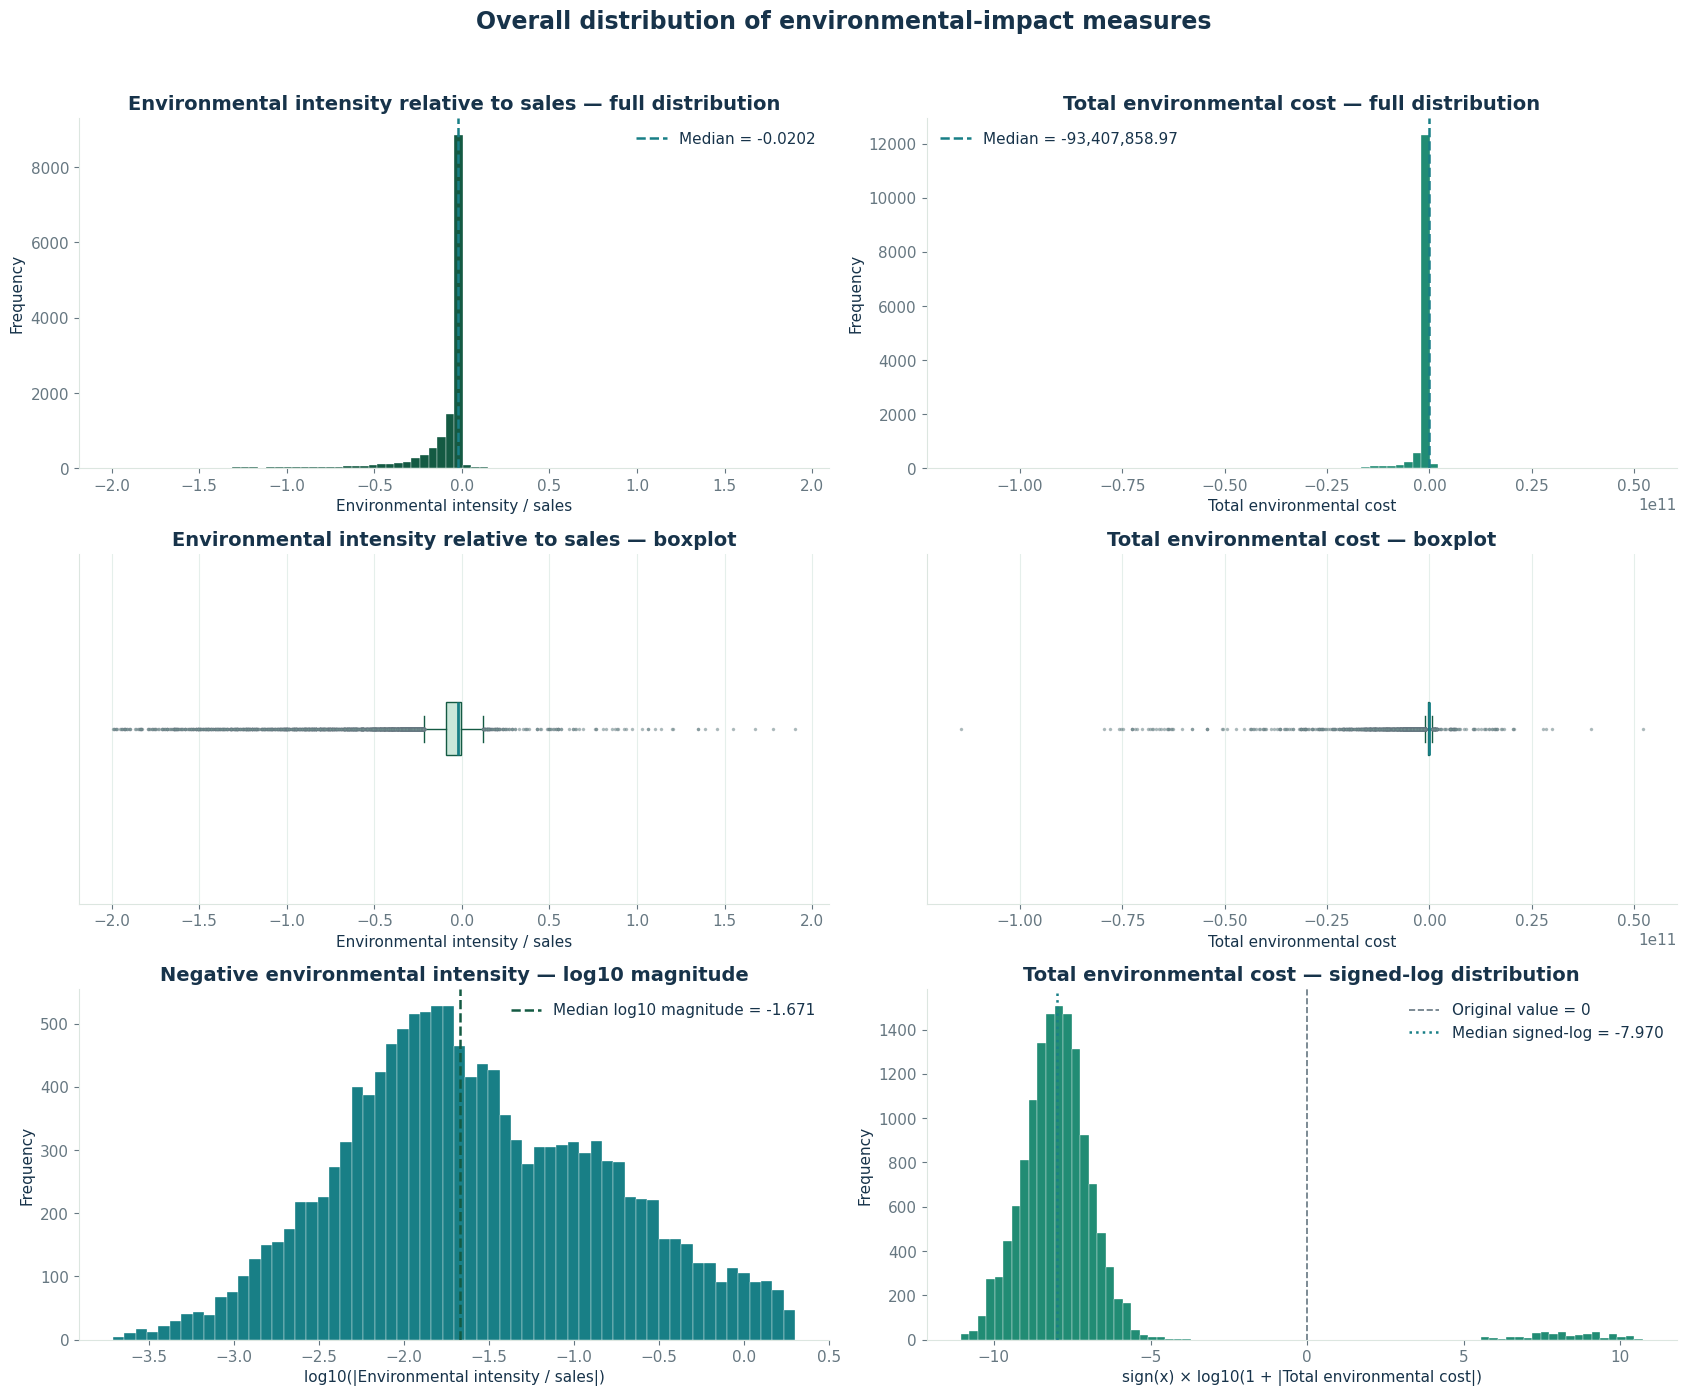

Negative observations shown in log-magnitude view: 13,667 (97.52% of non-missing intensity observations)
Original total environmental cost minimum: -114,442,352,167.86
Original total environmental cost maximum: 52,111,018,150.99


In [8]:
# Combined 3x2 panel: full distributions, boxplots, and log-transformed distributions.
intensity = df[INTENSITY].dropna()
cost = df[TOTAL_COST].dropna()

negative_intensity = df.loc[df[INTENSITY] < 0, INTENSITY].dropna()
log_negative_intensity = np.log10(negative_intensity.abs())
signed_log_cost = np.sign(cost) * np.log10(1 + cost.abs())

fig, axes = plt.subplots(3, 2, figsize=(17, 14))
fig.suptitle(
    "Overall distribution of environmental-impact measures",
    fontsize=17, fontweight="bold", color=COLORS["navy"], y=0.995
)

# Row 1: Full-distribution histograms
axes[0, 0].hist(
    intensity, bins=80, color=COLORS["forest"],
    edgecolor=COLORS["background"], linewidth=0.25
)
axes[0, 0].axvline(
    intensity.median(), color=COLORS["teal"], linestyle="--", linewidth=1.8,
    label=f"Median = {intensity.median():.4f}"
)
axes[0, 0].set_title("Environmental intensity relative to sales — full distribution")
axes[0, 0].set_xlabel("Environmental intensity / sales")
axes[0, 0].set_ylabel("Frequency")
axes[0, 0].legend()

axes[0, 1].hist(
    cost, bins=80, color=COLORS["green"],
    edgecolor=COLORS["background"], linewidth=0.25
)
axes[0, 1].axvline(
    cost.median(), color=COLORS["teal"], linestyle="--", linewidth=1.8,
    label=f"Median = {cost.median():,.2f}"
)
axes[0, 1].set_title("Total environmental cost — full distribution")
axes[0, 1].set_xlabel("Total environmental cost")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].legend()

# Row 2: Raw-scale boxplots
axes[1, 0].boxplot(
    intensity, vert=False, showfliers=True, patch_artist=True,
    boxprops={"facecolor": COLORS["mint"], "edgecolor": COLORS["forest"]},
    medianprops={"color": COLORS["teal"], "linewidth": 2},
    whiskerprops={"color": COLORS["forest"]},
    capprops={"color": COLORS["forest"]},
    flierprops={
        "marker": ".", "markerfacecolor": COLORS["sage"],
        "markeredgecolor": COLORS["gray"], "alpha": 0.45, "markersize": 3
    },
)
axes[1, 0].set_title("Environmental intensity relative to sales — boxplot")
axes[1, 0].set_xlabel("Environmental intensity / sales")
axes[1, 0].set_yticks([])
axes[1, 0].grid(axis="x", color=COLORS["grid"])

axes[1, 1].boxplot(
    cost, vert=False, showfliers=True, patch_artist=True,
    boxprops={"facecolor": COLORS["mint"], "edgecolor": COLORS["forest"]},
    medianprops={"color": COLORS["teal"], "linewidth": 2},
    whiskerprops={"color": COLORS["forest"]},
    capprops={"color": COLORS["forest"]},
    flierprops={
        "marker": ".", "markerfacecolor": COLORS["sage"],
        "markeredgecolor": COLORS["gray"], "alpha": 0.45, "markersize": 3
    },
)
axes[1, 1].set_title("Total environmental cost — boxplot")
axes[1, 1].set_xlabel("Total environmental cost")
axes[1, 1].set_yticks([])
axes[1, 1].grid(axis="x", color=COLORS["grid"])

# Row 3: Log-transformed histograms
axes[2, 0].hist(
    log_negative_intensity, bins=60, color=COLORS["teal"],
    edgecolor=COLORS["background"], linewidth=0.25
)
axes[2, 0].axvline(
    log_negative_intensity.median(), color=COLORS["forest"], linestyle="--",
    linewidth=1.8,
    label=f"Median log10 magnitude = {log_negative_intensity.median():.3f}"
)
axes[2, 0].set_title("Negative environmental intensity — log10 magnitude")
axes[2, 0].set_xlabel("log10(|Environmental intensity / sales|)")
axes[2, 0].set_ylabel("Frequency")
axes[2, 0].legend()

axes[2, 1].hist(
    signed_log_cost, bins=80, color=COLORS["green"],
    edgecolor=COLORS["background"], linewidth=0.25
)
axes[2, 1].axvline(
    0, color=COLORS["gray"], linestyle="--", linewidth=1.2,
    label="Original value = 0"
)
axes[2, 1].axvline(
    signed_log_cost.median(), color=COLORS["teal"], linestyle=":",
    linewidth=1.8,
    label=f"Median signed-log = {signed_log_cost.median():.3f}"
)
axes[2, 1].set_title("Total environmental cost — signed-log distribution")
axes[2, 1].set_xlabel("sign(x) × log10(1 + |Total environmental cost|)")
axes[2, 1].set_ylabel("Frequency")
axes[2, 1].legend()

# Consistent theme across the six panels.
for ax in axes.flat:
    ax.set_facecolor(COLORS["background"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#DCE6E0")
    ax.spines["bottom"].set_color("#DCE6E0")
    ax.tick_params(colors=COLORS["gray"])

plt.tight_layout(rect=[0, 0, 1, 0.975])
plt.show()

print(
    f"Negative observations shown in log-magnitude view: {len(negative_intensity):,} "
    f"({len(negative_intensity) / df[INTENSITY].notna().sum() * 100:.2f}% of non-missing intensity observations)"
)
print(f"Original total environmental cost minimum: {cost.min():,.2f}")
print(f"Original total environmental cost maximum: {cost.max():,.2f}")

### Interpretation checklist — Section 1

After running the cells, summarize only what the outputs support:

- Is the distribution symmetric or strongly skewed?
- Is the median substantially different from the mean?
- How large is the P1–P99 range relative to the full range?
- What proportion of observations is negative, zero, or positive?
- Are a small number of observations driving the extreme tail?
- Does the **log-magnitude intensity view** reveal structure among the negative observations that is hidden on the raw scale?
- Does the **signed-log total-cost view** show a clearer central distribution once the extreme −114.44B tail is compressed?

Keep this section focused on unconditional distributions; industry-, country-, and year-level comparisons are examined in Section 5.


# 2. Impact composition — safeguard contributions

`total_environmental_cost` is linked to eight safeguard dimensions.

This section asks:

> **Which safeguard dimensions account for the largest share of the observed environmental impact?**

Two contribution measures are reported:

1. **Net contribution share** — based on signed totals. This preserves the accounting relationship between components and total cost.
2. **Absolute-magnitude share** — based on absolute component values. This is useful when positive and negative component values offset each other.

A reconstruction check is performed first to verify how closely the safeguards reproduce `total_environmental_cost`.


In [9]:
# Reconstruct total environmental cost from safeguard components.
# This is a data-consistency check, not a substantive correlation analysis.
df["_safeguard_sum"] = df[SAFEGUARD_COLS].sum(axis=1, min_count=1)
df["_reconstruction_gap"] = df[TOTAL_COST] - df["_safeguard_sum"]

reconstruction_check = pd.Series({
    "Mean absolute reconstruction gap": df["_reconstruction_gap"].abs().mean(),
    "Median absolute reconstruction gap": df["_reconstruction_gap"].abs().median(),
    "Maximum absolute reconstruction gap": df["_reconstruction_gap"].abs().max(),
    "Reconstruction correlation (validation only)":
        df[[TOTAL_COST, "_safeguard_sum"]].corr().iloc[0, 1],
})

display(reconstruction_check.to_frame("Value"))


,Value
Mean absolute reconstruction gap,0.057738
Median absolute reconstruction gap,0.000000
Maximum absolute reconstruction gap,89.418892
Reconstruction correlation (validation only),1.000000


In [10]:
# Contribution table
component_totals = df[SAFEGUARD_COLS].sum()
reported_total = df[TOTAL_COST].sum()

net_share = component_totals / reported_total * 100

absolute_component_totals = df[SAFEGUARD_COLS].abs().sum()
absolute_share = absolute_component_totals / absolute_component_totals.sum() * 100

composition = pd.DataFrame({
    "Signed total": component_totals,
    "Net contribution %": net_share,
    "Absolute magnitude": absolute_component_totals,
    "Absolute magnitude share %": absolute_share,
}).sort_values("Absolute magnitude share %", ascending=False)

display(composition)


,Signed total,Net contribution %,Absolute magnitude,Absolute magnitude share %
working_capacity,"-13,954,678,229,939.505859",88.120017,"15,421,116,547,116.613281",87.070260
water_production_capacity_drinking_water_and_irrigation_water,"-1,590,902,567,228.985352",10.046119,"1,971,316,581,368.854004",11.130390
crop_production_capacity,"-180,934,396,137.825500",1.142552,"200,876,061,639.813293",1.134181
abiotic_resources,"-63,728,480,780.513832",0.402428,"63,728,480,780.513832",0.359822
meat_production_capacity,"-42,066,976,412.933167",0.265642,"46,685,239,557.791031",0.263593
fish_production_capacity,"-4,044,813,930.220466",0.025542,"4,240,727,485.402086",0.023944
wood_production_capacity,"1,599,509,314.945479",-0.010100,"1,882,255,112.590433",0.010628
biodiversity,"-1,235,303,685.008165",0.007801,"1,272,253,712.116569",0.007183


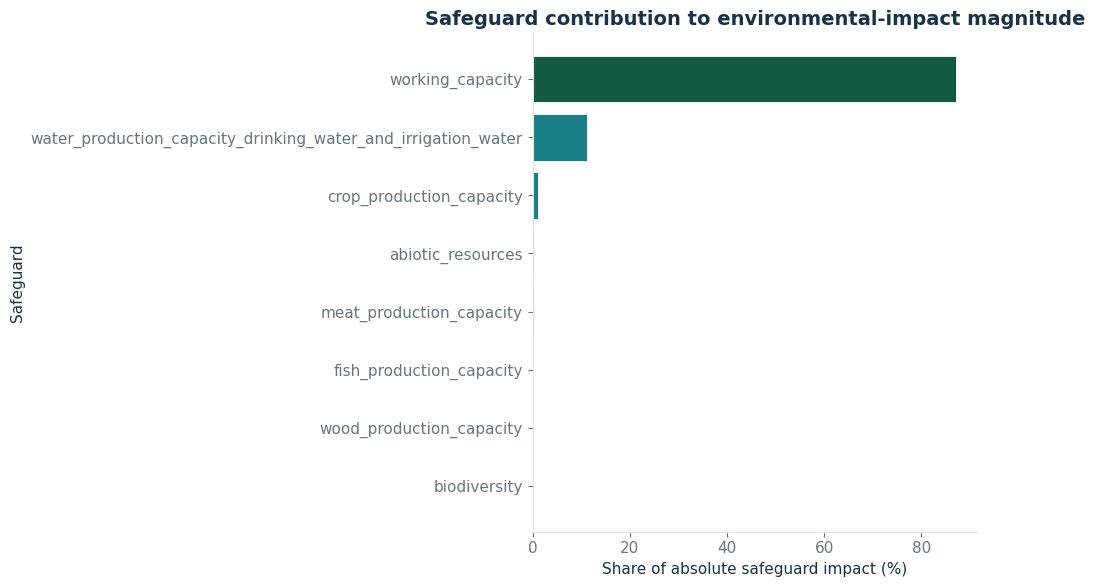

In [11]:
# Safeguard contribution chart
plot_data = composition["Absolute magnitude share %"].sort_values()

plt.figure(figsize=(10, 6))
bar_colors = [
    COLORS["mint"], COLORS["sage"], COLORS["sage"], COLORS["green"],
    COLORS["green"], COLORS["teal"], COLORS["teal"], COLORS["forest"],
][:len(plot_data)]
plt.barh(plot_data.index, plot_data.values, color=bar_colors, edgecolor=COLORS["background"], linewidth=0.6)
plt.title("Safeguard contribution to environmental-impact magnitude")
plt.xlabel("Share of absolute safeguard impact (%)")
plt.ylabel("Safeguard")
plt.tight_layout()
plt.show()


### Interpretation guide — Section 2

Use the contribution table and chart to describe which safeguard dimensions account for the largest share of absolute environmental-impact magnitude.

The reconstruction check in the preceding cell is a **data-consistency diagnostic only**. Since `total_environmental_cost` is constructed from the safeguard components, a near-perfect reconstruction or correlation is not a separate substantive finding. The useful EDA insight here is the **composition of impact across components**, not the fact that the components add up to the total.


# 3. Outliers & concentration

This section separates two different questions:

### 3.1 Extreme environmental intensity
Are there unusually extreme company-year observations in environmental intensity?

### 3.2 Environmental-cost concentration
Is a large share of the observed environmental cost concentrated among a small number of companies?

Extreme values are **identified, not automatically removed**.


## 3.1 Extreme environmental intensity

Two common diagnostics are used:

- **Percentile rule:** observations outside P1–P99;
- **IQR rule:** observations outside Q1 − 1.5×IQR or Q3 + 1.5×IQR.

Because this variable is highly skewed, the percentile rule is especially useful for descriptive inspection.


In [12]:
s = df[INTENSITY].dropna()

q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1

iqr_lower = q1 - 1.5 * iqr
iqr_upper = q3 + 1.5 * iqr

p1 = s.quantile(0.01)
p99 = s.quantile(0.99)

outlier_summary = pd.Series({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "IQR lower fence": iqr_lower,
    "IQR upper fence": iqr_upper,
    "IQR outlier N": ((s < iqr_lower) | (s > iqr_upper)).sum(),
    "IQR outlier %": ((s < iqr_lower) | (s > iqr_upper)).mean() * 100,
    "P1": p1,
    "P99": p99,
    "Outside P1–P99 N": ((s < p1) | (s > p99)).sum(),
    "Outside P1–P99 %": ((s < p1) | (s > p99)).mean() * 100,
})

display(outlier_summary.to_frame("Value"))


,Value
Q1,-0.090633
Q3,-0.006860
IQR,0.083773
IQR lower fence,-0.216293
IQR upper fence,0.118800
IQR outlier N,"2,005.000000"
IQR outlier %,14.306101
P1,-1.434013
P99,0.102486
Outside P1–P99 N,282.000000


In [13]:
# Most negative and most positive intensity observations
extreme_cols = [
    "company_name",
    "year",
    "country",
    "industry_exiobase",
    INTENSITY,
    TOTAL_COST,
    IMPUTED,
]

most_negative = (
    df[extreme_cols]
    .dropna(subset=[INTENSITY])
    .nsmallest(15, INTENSITY)
)

most_positive = (
    df[extreme_cols]
    .dropna(subset=[INTENSITY])
    .nlargest(15, INTENSITY)
)

print("15 MOST NEGATIVE ENVIRONMENTAL-INTENSITY OBSERVATIONS")
display(most_negative)

print("\n15 MOST POSITIVE ENVIRONMENTAL-INTENSITY OBSERVATIONS")
display(most_positive)


15 MOST NEGATIVE ENVIRONMENTAL-INTENSITY OBSERVATIONS


,company_name,year,country,industry_exiobase,environmental_intensity_sales,total_environmental_cost,pct_imputed
11699,OGE ENERGY CORP,2012,UNITED STATES OF AMERICA,Production of electricity nec,-1.992787,"-7,337,043,943.189479",0.041715
4334,AGGREKO PLC,2017,UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN I...,Other service activities (93),-1.988844,"-4,654,923,981.826386",0.000187
4928,ALLIANT ENERGY CORP,2016,UNITED STATES OF AMERICA,Production of electricity nec,-1.988168,"-6,600,718,846.044235",0.015065
10269,AGGREKO PLC,2013,UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN I...,Other service activities (93),-1.976446,"-5,149,042,088.309377",0.000164
21,HACI OMER SABANCI HOLDING AS,2019,TURKEY,Activities of membership organisation n.e.c. (91),-1.976404,"-6,240,338,482.033154",0.125488
10965,OMV PETROM,2012,ROMANIA,Extraction of crude petroleum and services rel...,-1.970553,"-15,364,180,116.718060",0.004716
12779,OGE ENERGY CORP,2011,UNITED STATES OF AMERICA,Production of electricity nec,-1.953126,"-7,666,997,227.520163",0.031008
9141,POLSKA GRUPA ENERGETYCZNA SA,2014,POLAND,Production of electricity nec,-1.948901,"-15,437,102,579.793150",0.000585
11700,POLSKA GRUPA ENERGETYCZNA SA,2012,POLAND,Production of electricity nec,-1.944206,"-19,175,984,365.501652",0.001495
9129,RATCH GROUP PUBLIC CO LTD,2014,THAILAND,Production of electricity by hydro,-1.939788,"-3,241,085,459.129010",0.000982



15 MOST POSITIVE ENVIRONMENTAL-INTENSITY OBSERVATIONS


,company_name,year,country,industry_exiobase,environmental_intensity_sales,total_environmental_cost,pct_imputed
1648,TEEKAY TANKERS LTD,2019,CANADA,Transport via pipelines,1.903596,"1,796,836,955.066575",0.051577
6538,PJSC MINING AND METALLURGICA,2016,RUSSIAN FEDERATION,Quarrying of sand and clay,1.774254,"15,818,095,943.520510",0.002268
6974,ROYAL BANK OF CANADA,2015,CANADA,"Financial intermediation, except insurance and...",1.676431,"52,111,018,150.987747",0.000999
4671,PJSC MINING AND METALLURGICA,2017,RUSSIAN FEDERATION,Quarrying of sand and clay,1.547235,"14,425,128,805.065069",0.002418
3015,PJSC MINING AND METALLURGICA,2018,RUSSIAN FEDERATION,Quarrying of sand and clay,1.454372,"15,266,074,046.043539",0.002621
3592,SENEX ENERGY LTD,2017,AUSTRALIA,Extraction of crude petroleum and services rel...,1.390194,"50,703,494.771697",0.134854
1482,WASTE CONNECTIONS INC,2019,CANADA,Real estate activities (70),1.350965,"7,415,452,346.251956",0.000214
13320,STANDARD BANK GROUP LTD,2010,SOUTH AFRICA,"Financial intermediation, except insurance and...",1.348845,"29,949,673,812.633999",0.000061
541,COCA-COLA EUROPACIFIC PARTNE,2019,UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN I...,Manufacture of beverages,1.207315,"16,216,661,998.120880",0.002927
1647,COSCO SHIPPING ENERGY,2019,CHINA,Transport via pipelines,1.201374,"2,367,464,064.195148",0.002858


In [14]:
# Do the same companies repeatedly appear in the extreme 1% tail?
tail_cutoff = df[INTENSITY].quantile(0.01)

extreme_company_frequency = (
    df.loc[df[INTENSITY] <= tail_cutoff]
      .groupby("company_name")
      .size()
      .sort_values(ascending=False)
      .rename("Extreme observations")
      .to_frame()
)

display(extreme_company_frequency.head(20))


,Extreme observations
company_name,
NRG ENERGY INC,8
PPC LTD,8
KEPCO-KOREA ELEC POWER CORP,6
BUZZI UNICEM SPA,5
RATCH GROUP PUBLIC CO LTD,5
AGGREKO PLC,4
ELEC POWER DEVELOPMENT CO,4
IDACORP INC,4
POLSKA GRUPA ENERGETYCZNA SA,3


## 3.2 Pareto / concentration analysis

For concentration, environmental cost is aggregated to the **company level** using absolute cost magnitude:

`company absolute environmental cost = Σ |total environmental cost|`

Companies are then ranked from highest to lowest impact magnitude.

> **Caveat:** the dataset is an unbalanced panel, so companies observed in more years have more opportunities to accumulate total cost. This chart describes concentration in the observed dataset; it is not a causal or time-normalized company ranking.


In [15]:
company_impact = (
    df.assign(abs_environmental_cost=df[TOTAL_COST].abs())
      .groupby("company_name", as_index=False)
      .agg(
          total_absolute_environmental_cost=("abs_environmental_cost", "sum"),
          observations=("year", "size"),
          years_observed=("year", "nunique"),
      )
      .sort_values("total_absolute_environmental_cost", ascending=False)
      .reset_index(drop=True)
)

company_impact["cumulative_cost"] = company_impact["total_absolute_environmental_cost"].cumsum()
company_impact["cumulative_cost_share"] = (
    company_impact["cumulative_cost"]
    / company_impact["total_absolute_environmental_cost"].sum()
)
company_impact["cumulative_company_share"] = (
    np.arange(1, len(company_impact) + 1) / len(company_impact)
)

display(company_impact.head(20))


,company_name,total_absolute_environmental_cost,observations,years_observed,cumulative_cost,cumulative_cost_share,cumulative_company_share
0,ARCELORMITTAL,"664,253,144,251.722168",10,10,"664,253,144,251.722168",0.037846,0.000402
1,KEPCO-KOREA ELEC POWER CORP,"664,152,476,894.943970",9,9,"1,328,405,621,146.666016",0.075687,0.000805
2,GAZPROM PJSC,"442,996,132,427.225342",9,9,"1,771,401,753,573.891357",0.100927,0.001207
3,EXXON MOBIL CORP,"389,578,004,438.420654",10,10,"2,160,979,758,012.312012",0.123123,0.001610
4,ENI SPA,"346,436,958,781.830505",10,10,"2,507,416,716,794.142578",0.142862,0.002012
5,HOLCIM LTD,"312,558,611,417.484863",9,9,"2,819,975,328,211.627441",0.160670,0.002414
6,POSCO HOLDINGS INC,"296,388,157,625.095398",10,10,"3,116,363,485,836.722656",0.177557,0.002817
7,TOKYO ELECTRIC POWER CO HOLD,"269,521,256,929.628601",8,8,"3,385,884,742,766.351074",0.192913,0.003219
8,RWE AG,"244,703,045,870.781830",5,5,"3,630,587,788,637.132812",0.206855,0.003622
9,ENGIE SA,"217,106,775,350.955200",7,7,"3,847,694,563,988.087891",0.219225,0.004024


In [16]:
def top_company_share(company_df, pct):
    n_top = max(1, int(np.ceil(len(company_df) * pct)))
    share = (
        company_df.head(n_top)["total_absolute_environmental_cost"].sum()
        / company_df["total_absolute_environmental_cost"].sum()
        * 100
    )
    return n_top, share

concentration_rows = []
for pct in [0.01, 0.05, 0.10, 0.20]:
    n_top, share = top_company_share(company_impact, pct)
    concentration_rows.append({
        "Top company share": f"{int(pct*100)}%",
        "Number of companies": n_top,
        "Share of absolute environmental cost (%)": share,
    })

concentration_table = pd.DataFrame(concentration_rows)
display(concentration_table)


,Top company share,Number of companies,Share of absolute environmental cost (%)
0,1%,25,36.368434
1,5%,125,72.403284
2,10%,249,84.910466
3,20%,497,93.808992


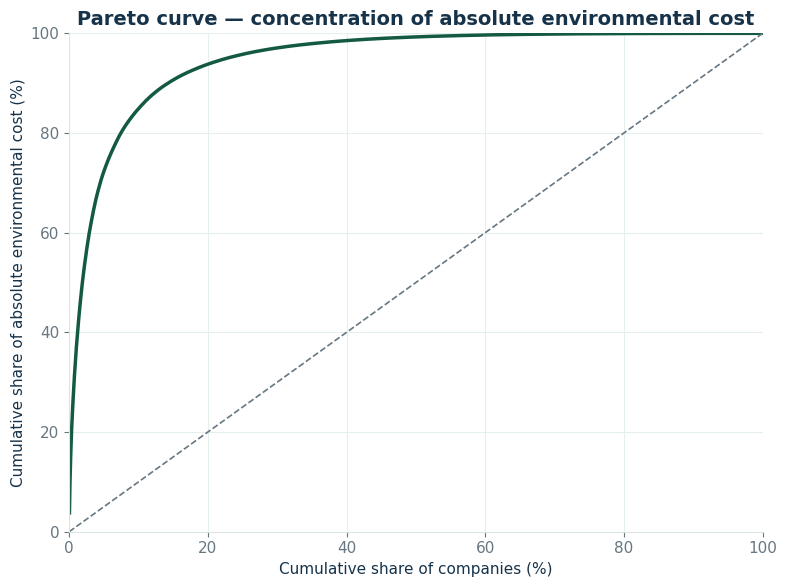

In [17]:
plt.figure(figsize=(8, 6))
plt.plot(
    company_impact["cumulative_company_share"] * 100,
    company_impact["cumulative_cost_share"] * 100,
    color=COLORS["forest"], linewidth=2.5
)
plt.plot([0, 100], [0, 100], color=COLORS["gray"], linestyle="--", linewidth=1.2)
plt.title("Pareto curve — concentration of absolute environmental cost")
plt.xlabel("Cumulative share of companies (%)")
plt.ylabel("Cumulative share of absolute environmental cost (%)")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid(color=COLORS["grid"], alpha=1)
plt.tight_layout()
plt.show()


### Interpretation checklist — Section 3

For extreme intensity:

- How far are the most negative observations from the bulk of the data?
- Do the same firms repeatedly appear in the extreme tail?
- Are extreme observations also associated with high `% imputed` values?

For concentration:

- What share of absolute environmental cost is accounted for by the top 1%, 5%, and 10% of companies?
- Does the Pareto curve deviate strongly from the 45-degree equality line?
- Is environmental impact broadly distributed or heavily concentrated?

Do **not** delete an observation simply because it is extreme. Removal requires a defensible data-quality or methodological reason.


# 4. Variable relationships — correlation & reliability

This final EDA block examines:

1. **Exploratory relationships among environmental variables**
2. **Whether the primary intensity measure is systematically associated with `% imputed`**

Because several variables are strongly skewed, **Spearman rank correlation** is the primary correlation measure. A Pearson matrix is also produced for comparison.

**Interpretation guardrail:** `total_environmental_cost` is constructed from safeguard components. Correlations between the total and its components are therefore partly mechanical and should not be presented as independent findings. The main reliability question is the relationship between `% imputed` and the primary outcome, `environmental_intensity_sales`.

Correlation is descriptive, not causal evidence.


In [18]:
relationship_cols = [
    INTENSITY,
    TOTAL_COST,
    IMPUTED,
] + SAFEGUARD_COLS

spearman_corr = df[relationship_cols].corr(method="spearman")
pearson_corr = df[relationship_cols].corr(method="pearson")

print("SPEARMAN CORRELATION")
display(spearman_corr.round(3))

print()
print("PEARSON CORRELATION")
display(pearson_corr.round(3))

print()
print(
    "Interpretation note: correlations between total environmental cost "
    "and its safeguard components are diagnostic only because the total is "
    "constructed from those components. Do not report them as independent findings."
)


SPEARMAN CORRELATION


,environmental_intensity_sales,total_environmental_cost,pct_imputed,working_capacity,fish_production_capacity,crop_production_capacity,meat_production_capacity,biodiversity,abiotic_resources,water_production_capacity_drinking_water_and_irrigation_water,wood_production_capacity
environmental_intensity_sales,1.000000,0.708000,0.341000,0.680000,0.628000,0.675000,0.676000,0.654000,0.342000,0.619000,-0.226000
total_environmental_cost,0.708000,1.000000,0.248000,0.984000,0.936000,0.979000,0.980000,0.960000,0.652000,0.814000,-0.499000
pct_imputed,0.341000,0.248000,1.000000,0.250000,0.262000,0.256000,0.258000,0.256000,-0.257000,0.165000,-0.069000
working_capacity,0.680000,0.984000,0.250000,1.000000,0.947000,0.997000,0.998000,0.971000,0.651000,0.760000,-0.500000
fish_production_capacity,0.628000,0.936000,0.262000,0.947000,1.000000,0.942000,0.942000,0.981000,0.687000,0.754000,-0.598000
crop_production_capacity,0.675000,0.979000,0.256000,0.997000,0.942000,1.000000,0.999000,0.967000,0.645000,0.754000,-0.499000
meat_production_capacity,0.676000,0.980000,0.258000,0.998000,0.942000,0.999000,1.000000,0.967000,0.644000,0.754000,-0.499000
biodiversity,0.654000,0.960000,0.256000,0.971000,0.981000,0.967000,0.967000,1.000000,0.676000,0.759000,-0.561000
abiotic_resources,0.342000,0.652000,-0.257000,0.651000,0.687000,0.645000,0.644000,0.676000,1.000000,0.588000,-0.444000
water_production_capacity_drinking_water_and_irrigation_water,0.619000,0.814000,0.165000,0.760000,0.754000,0.754000,0.754000,0.759000,0.588000,1.000000,-0.420000



PEARSON CORRELATION


,environmental_intensity_sales,total_environmental_cost,pct_imputed,working_capacity,fish_production_capacity,crop_production_capacity,meat_production_capacity,biodiversity,abiotic_resources,water_production_capacity_drinking_water_and_irrigation_water,wood_production_capacity
environmental_intensity_sales,1.000000,0.502000,0.116000,0.485000,0.444000,0.490000,0.493000,0.044000,0.117000,0.231000,-0.086000
total_environmental_cost,0.502000,1.000000,0.036000,0.964000,0.923000,0.960000,0.960000,0.084000,0.411000,0.457000,-0.229000
pct_imputed,0.116000,0.036000,1.000000,0.033000,0.061000,0.040000,0.041000,-0.026000,-0.048000,0.027000,-0.119000
working_capacity,0.485000,0.964000,0.033000,1.000000,0.952000,0.998000,0.998000,0.086000,0.419000,0.205000,-0.231000
fish_production_capacity,0.444000,0.923000,0.061000,0.952000,1.000000,0.950000,0.952000,0.084000,0.386000,0.214000,-0.449000
crop_production_capacity,0.490000,0.960000,0.040000,0.998000,0.950000,1.000000,1.000000,0.086000,0.401000,0.197000,-0.259000
meat_production_capacity,0.493000,0.960000,0.041000,0.998000,0.952000,1.000000,1.000000,0.086000,0.404000,0.197000,-0.256000
biodiversity,0.044000,0.084000,-0.026000,0.086000,0.084000,0.086000,0.086000,1.000000,0.033000,0.020000,-0.027000
abiotic_resources,0.117000,0.411000,-0.048000,0.419000,0.386000,0.401000,0.404000,0.033000,1.000000,0.051000,0.004000
water_production_capacity_drinking_water_and_irrigation_water,0.231000,0.457000,0.027000,0.205000,0.214000,0.197000,0.197000,0.020000,0.051000,1.000000,-0.078000



Interpretation note: correlations between total environmental cost and its safeguard components are diagnostic only because the total is constructed from those components. Do not report them as independent findings.


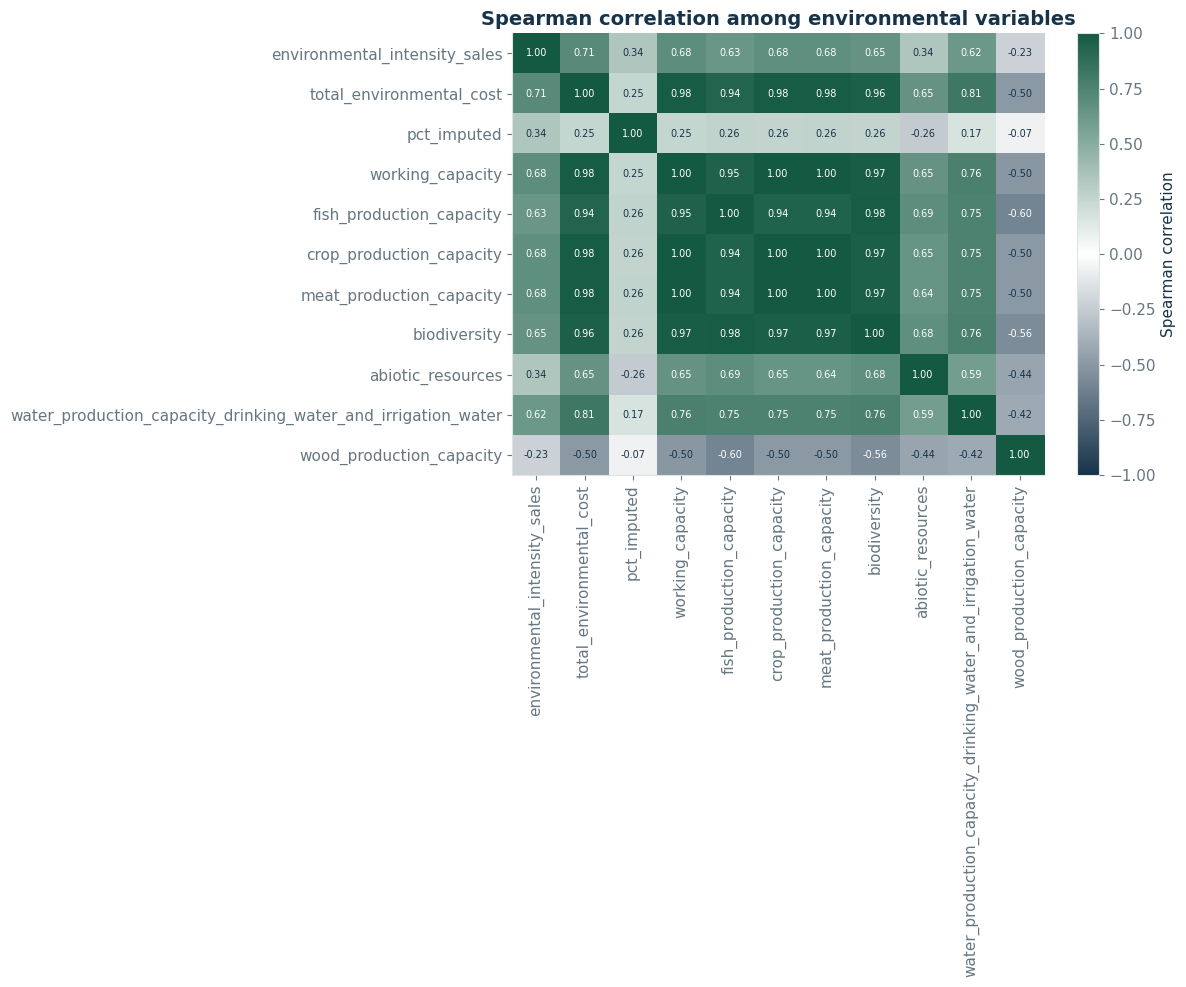

In [19]:
# Spearman heatmap using matplotlib only
matrix = spearman_corr.values
labels = spearman_corr.columns

fig, ax = plt.subplots(figsize=(12, 10))
cmap = LinearSegmentedColormap.from_list(
    "environmental_correlation",
    [COLORS["navy"], COLORS["background"], COLORS["forest"]],
)
im = ax.imshow(matrix, vmin=-1, vmax=1, aspect="auto", cmap=cmap)

ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=90)
ax.set_yticklabels(labels)

for i in range(len(labels)):
    for j in range(len(labels)):
        text_color = "white" if abs(matrix[i, j]) >= 0.55 else COLORS["navy"]
        ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=7, color=text_color)

fig.colorbar(im, ax=ax, label="Spearman correlation")
ax.set_title("Spearman correlation among environmental variables")
plt.tight_layout()
plt.show()


## 4.1 Reliability check: `% imputed` and environmental intensity

This is not another cleaning step. The purpose is to ask an analytical reliability question:

> **Do observations with more imputed data show systematically different environmental-intensity values?**

### Scale check

`pct_imputed` is stored as a **proportion**, not as a 0–100 percentage.  
For example, `0.05 = 5%` and `0.20 = 20%`.

Before creating groups, the notebook therefore prints `df[IMPUTED].describe()` to verify the observed scale.

The analysis includes:

- scale verification using descriptive statistics;
- Spearman correlation;
- imputation bands;
- median and IQR of environmental intensity by band;
- a sensitivity comparison between the full sample and observations with lower imputation.

> **Interpretation caution:** imputation is based partly on industry-level information. Therefore, an association between `% imputed` and environmental intensity may reflect **industry composition or systematic differences in data availability**, rather than measurement bias itself. Separating these explanations belongs to the subsequent research-question analysis, especially RQ2.


In [20]:
# Confirm the scale of pct_imputed before defining percentage bands
print("pct_imputed scale check")
display(df[IMPUTED].describe().to_frame("Value"))

# Direct rank relationship between imputation and environmental intensity
reliability_corr = (
    df[[IMPUTED, INTENSITY]]
    .dropna()
    .corr(method="spearman")
    .iloc[0, 1]
)

print(
    f"\nSpearman correlation: pct_imputed vs environmental_intensity_sales "
    f"= {reliability_corr:.4f}"
)


pct_imputed scale check


,Value
count,"14,015.000000"
mean,0.065792
std,0.067400
min,0.000000
25%,0.011455
50%,0.039495
75%,0.103894
max,0.249796



Spearman correlation: pct_imputed vs environmental_intensity_sales = 0.3411


In [21]:
# Create interpretable imputation groups.
# pct_imputed is stored as a PROPORTION:
# 0.05 = 5%, 0.10 = 10%, 0.20 = 20%.
# right=True means, for example, 0.05 belongs to the ≤5% group.

bins = [-np.inf, 0.05, 0.10, 0.20, np.inf]
labels = ["≤5%", ">5–10%", ">10–20%", ">20%"]

df["_imputation_group"] = pd.cut(
    df[IMPUTED],
    bins=bins,
    labels=labels,
    right=True
)

imputation_summary = (
    df.groupby("_imputation_group", observed=False)[INTENSITY]
      .agg(
          N="count",
          Mean="mean",
          Median="median",
          Std="std",
          P25=lambda x: x.quantile(0.25),
          P75=lambda x: x.quantile(0.75),
      )
)

imputation_summary["IQR"] = (
    imputation_summary["P75"] - imputation_summary["P25"]
)

display(imputation_summary)


,N,Mean,Median,Std,P25,P75,IQR
_imputation_group,,,,,,,
≤5%,7885,-0.138746,-0.032172,0.309601,-0.119486,-0.011523,0.107962
>5–10%,2477,-0.079874,-0.014863,0.195635,-0.049204,-0.005088,0.044116
>10–20%,2723,-0.076885,-0.009070,0.209949,-0.035539,-0.002542,0.032996
>20%,930,-0.061995,-0.007712,0.164833,-0.030142,-0.001797,0.028345


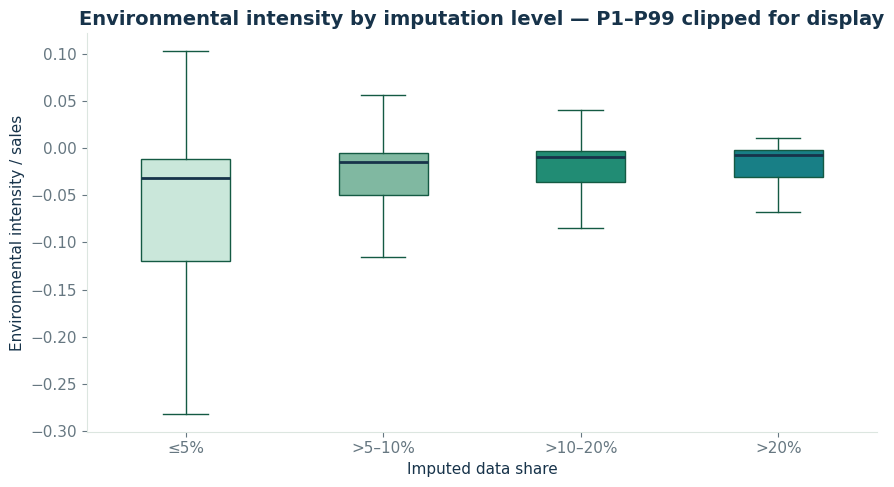

In [22]:
# Boxplots by imputation group.
# Values are clipped to P1–P99 for visualization only.
plot_df = df[[INTENSITY, "_imputation_group"]].dropna().copy()
lo, hi = plot_df[INTENSITY].quantile([0.01, 0.99])
plot_df["_intensity_clipped"] = plot_df[INTENSITY].clip(lo, hi)

group_order = ["≤5%", ">5–10%", ">10–20%", ">20%"]
box_data = [
    plot_df.loc[plot_df["_imputation_group"] == g, "_intensity_clipped"].values
    for g in group_order
]

plt.figure(figsize=(9, 5))
bp = plt.boxplot(
    box_data, labels=group_order, showfliers=False, patch_artist=True,
    boxprops={"edgecolor": COLORS["forest"]},
    medianprops={"color": COLORS["navy"], "linewidth": 2},
    whiskerprops={"color": COLORS["forest"]},
    capprops={"color": COLORS["forest"]},
)
for patch, fill_color in zip(bp["boxes"], [COLORS["mint"], COLORS["sage"], COLORS["green"], COLORS["teal"]]):
    patch.set_facecolor(fill_color)
plt.title("Environmental intensity by imputation level — P1–P99 clipped for display")
plt.xlabel("Imputed data share")
plt.ylabel("Environmental intensity / sales")
plt.tight_layout()
plt.show()


In [23]:
# Sensitivity comparison:
# pct_imputed is stored as a proportion, so:
# 0.20 = 20%, 0.10 = 10%, 0.05 = 5%.

def intensity_stats(data, label):
    s = data[INTENSITY].dropna()
    return pd.Series({
        "Sample": label,
        "N": len(s),
        "Mean": s.mean(),
        "Median": s.median(),
        "Std": s.std(),
        "P25": s.quantile(0.25),
        "P75": s.quantile(0.75),
        "P1": s.quantile(0.01),
        "P99": s.quantile(0.99),
    })

sensitivity = pd.DataFrame([
    intensity_stats(df, "Full sample"),
    intensity_stats(df[df[IMPUTED] <= 0.20], "Imputed ≤20%"),
    intensity_stats(df[df[IMPUTED] <= 0.10], "Imputed ≤10%"),
    intensity_stats(df[df[IMPUTED] <= 0.05], "Imputed ≤5%"),
]).set_index("Sample")

display(sensitivity)


,N,Mean,Median,Std,P25,P75,P1,P99
Sample,,,,,,,,
Full sample,14015,-0.111229,-0.020217,0.268402,-0.090633,-0.006860,-1.434013,0.102486
Imputed ≤20%,13085,-0.114728,-0.021405,0.273946,-0.094713,-0.007436,-1.452392,0.114092
Imputed ≤10%,10362,-0.124673,-0.026559,0.287601,-0.105446,-0.009502,-1.496722,0.146417
Imputed ≤5%,7885,-0.138746,-0.032172,0.309601,-0.119486,-0.011523,-1.559909,0.165494


### Interpretation guide — Section 4

For correlation:

- Compare Spearman and Pearson for the primary outcome and `% imputed`.
- Treat the relationship between `% imputed` and environmental intensity as an association, not proof of measurement bias.
- Do not present correlations between `total_environmental_cost` and its safeguard components as independent findings; the total is constructed from those components.

For reliability and sensitivity:

- Confirm that `% imputed` is stored on the **0–1 proportion scale**.
- Compare the median, IQR, and tail percentiles across the imputation bands.
- Compare the full sample with the ≤20%, ≤10%, and ≤5% samples.
- If the distribution shifts as the threshold tightens, report that sensitivity rather than claiming the results are fully stable.

Because imputation uses industry-level information, differences across imputation groups may also reflect industry composition or reporting coverage. EDA alone cannot separate these explanations; they should be examined in the later research-question analysis.


# EDA summary — main findings

The cleaned dataset contains **14,015 company-year observations**. The main descriptive findings are:

1. **Strongly skewed distributions.** About **97.52%** of observations have negative environmental intensity and total environmental cost. Environmental intensity has a mean of **−0.1112** and median of **−0.0202** (skewness **−3.29**). Total environmental cost is even more left-skewed (skewness **−8.60**), ranging from approximately **−114.44 billion** to **+52.11 billion** in the dataset's reported units. The gap between means and medians shows why the median and percentile ranges are important alongside averages.

2. **Impact magnitude is concentrated in two safeguard dimensions.** Working Capacity accounts for **87.07%** of the total absolute safeguard magnitude, followed by Water Production Capacity at **11.13%** and Crop Production Capacity at **1.13%**. Each remaining component contributes less than **0.4%**. These percentages describe the composition of absolute magnitude across the observed company-year records.

3. **Extreme intensity observations are present.** Approximately **14.31%** of observations fall outside the IQR fences, while **2.01%** fall outside the P1–P99 range. Several companies recur in the most-negative 1% tail. These values should be investigated where appropriate, but should not be removed solely because they are extreme.

4. **Environmental cost is highly concentrated across companies.** The top **1%** of companies account for **36.37%** of absolute environmental cost; the top **5%** account for **72.40%**, and the top **10%** account for **84.91%**. This aggregates absolute cost across observed years, so the unbalanced panel means companies with more observed years have more opportunities to accumulate cost.

5. **Imputation share is associated with the primary outcome.** Spearman correlation between `pct_imputed` and environmental intensity is **+0.3411**, compared with a Pearson correlation of approximately **+0.116**. The positive rank association indicates that higher imputation shares tend to accompany intensity values closer to zero. This is an association, not evidence that imputation itself causes the difference.

6. **Results are not fully stable across imputation thresholds.** The median intensity shifts from **−0.0202** in the full sample to **−0.0322** among observations with at most 5% imputed data; the mean shifts from **−0.1112** to **−0.1387**. The IQR also increases from approximately **0.0838** to **0.1080**. This sensitivity should be acknowledged, but it does not by itself establish imputation bias because industry composition and reporting coverage may differ between groups.

**Implication for subsequent analysis:** use robust descriptive statistics, investigate influential observations without automatically deleting them, and treat the imputation relationship as a potential data-reliability concern. The following section extends these descriptive checks by comparing environmental intensity across industries, countries, and years.


In [24]:
# Optional cleanup of helper columns created only for EDA
helper_cols = [
    "_safeguard_sum",
    "_reconstruction_gap",
    "_imputation_group",
]

df.drop(columns=[c for c in helper_cols if c in df.columns], inplace=True)

print("EDA helper columns removed from the in-memory dataframe.")


EDA helper columns removed from the in-memory dataframe.


# 5. Cross-sectional and temporal differences

This section extends the descriptive EDA by examining how `environmental_intensity_sales` varies across industries, countries, and years.

### Structure

1. **Industry differences**
2. **Country differences**
3. **Temporal differences**
   - Full sample
   - Balanced panel
   - Within-company change

### Interpretation of the outcome

`environmental_intensity_sales` is mainly negative in this dataset.

- **More negative** values indicate a larger environmental cost relative to sales.
- Values **closer to zero** indicate lower environmental cost intensity.

Because the outcome is strongly skewed, medians, IQRs, and non-parametric tests are emphasized. Statistical significance is interpreted alongside effect sizes and company-level robustness checks.


## 0. Setup

The cleaned dataset has already been loaded in the EDA setup above. This section reuses the same in-memory dataframe and applies the analysis-sample filter.

The analysis focuses on `environmental_intensity_sales`. Because the distribution contains heavy tails, the notebook emphasizes **median and IQR** rather than relying on the mean alone.


In [25]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import textwrap

from scipy.stats import kruskal, friedmanchisquare, wilcoxon, mannwhitneyu
from IPython.display import display

COLORS = {
    "forest": "#145A43",
    "green": "#218C74",
    "sage": "#80B8A1",
    "mint": "#CAE7DA",
    "teal": "#187F86",
    "navy": "#17334A",
    "gray": "#667781",
    "grid": "#E5EFEB",
    "background": "#FFFFFF"
}

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#DCE6E0",
    "axes.labelcolor": COLORS["navy"],
    "text.color": COLORS["navy"],
    "xtick.color": COLORS["gray"],
    "ytick.color": COLORS["gray"],
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "font.size": 11,
    "savefig.dpi": 300
})

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

INTENSITY = "environmental_intensity_sales"
INDUSTRY = "industry_exiobase"
COUNTRY = "country"
COMPANY = "company_name"
YEAR = "year"

required = [INTENSITY, INDUSTRY, COUNTRY, COMPANY, YEAR]
missing = [c for c in required if c not in df.columns]

if missing:
    raise KeyError(f"Missing required columns: {missing}")

df = df.dropna(subset=[INTENSITY, YEAR, COMPANY]).copy()
df[YEAR] = df[YEAR].astype(int)

print("Comparative EDA setup ready!")
print(f"Reusing loaded dataset: {DATA_PATH}")
print(f"Analysis sample: {len(df):,} observations")
print(f"Companies: {df[COMPANY].nunique():,}")
print(f"Years: {df[YEAR].min()}–{df[YEAR].max()}")
print(f"Industries: {df[INDUSTRY].nunique(dropna=True):,}")
print(f"Countries: {df[COUNTRY].nunique(dropna=True):,}")

negative_extreme_share = (df[INTENSITY] < -1).mean() * 100
positive_share = (df[INTENSITY] > 0).mean() * 100

print(f"Intensity < -1: {negative_extreme_share:.2f}% of observations")
print(f"Intensity > 0: {positive_share:.2f}% of observations")


Comparative EDA setup ready!
Reusing loaded dataset: cleaned_environmental_impact_data.xlsx
Analysis sample: 14,015 observations
Companies: 2,485
Years: 2010–2019
Industries: 56
Countries: 68
Intensity < -1: 2.58% of observations
Intensity > 0: 2.48% of observations


## Helper functions

Two reusable functions are used throughout the comparative EDA:

1. group-level descriptive statistics;
2. Kruskal–Wallis test with an **eta-squared H** effect size.

For the Kruskal–Wallis comparisons, the notebook reports:

- total groups and observations;
- groups and observations retained after the minimum-N rule;
- groups and observations excluded from the inferential comparison.

### Effect-size guide for eta-squared H

The notebook calculates:

\[
\eta_H^2 = \frac{H-k+1}{n-k}
\]

where \(H\) is the Kruskal–Wallis statistic, \(k\) is the number of groups included in the test, and \(n\) is the number of firm-year observations included in the test.

A rough interpretation used here is:

- `< 0.01`: negligible
- `0.01–0.06`: small
- `0.06–0.14`: moderate
- `≥ 0.14`: large

These thresholds are heuristics and should be interpreted together with the observed distributions and sample sizes.

> **Inference limitation:** company-year observations are not fully independent because the same company can appear in multiple years. The analysis therefore emphasizes effect sizes, descriptive patterns, and company-level robustness checks rather than p-values alone.


In [26]:
def grouped_summary(data, group_col, value_col=INTENSITY):
    out = (
        data.dropna(subset=[group_col, value_col])
            .groupby(group_col)
            .agg(
                N=(value_col, "count"),
                Companies=(COMPANY, "nunique"),
                Mean=(value_col, "mean"),
                Median=(value_col, "median"),
                Std=(value_col, "std"),
                P25=(value_col, lambda x: x.quantile(0.25)),
                P75=(value_col, lambda x: x.quantile(0.75)),
            )
    )
    out["IQR"] = out["P75"] - out["P25"]
    return out.sort_values("Median")


def kruskal_with_eta_h(data, group_col, value_col=INTENSITY, min_n=30):
    temp = data.dropna(subset=[group_col, value_col]).copy()

    counts = temp[group_col].value_counts()
    groups_total = len(counts)
    n_total = len(temp)

    eligible = counts[counts >= min_n].index
    filtered = temp[temp[group_col].isin(eligible)]

    grouped_arrays = [
        g[value_col].values
        for _, g in filtered.groupby(group_col)
    ]

    groups_tested = len(grouped_arrays)
    groups_excluded = groups_total - groups_tested
    n_tested = len(filtered)
    n_excluded = n_total - n_tested

    if groups_tested < 2:
        return {
            "Groups total": groups_total,
            "Groups tested": groups_tested,
            "Groups excluded": groups_excluded,
            "N total": n_total,
            "N tested": n_tested,
            "N excluded": n_excluded,
            "H": np.nan,
            "p-value": np.nan,
            "Eta-squared H": np.nan,
        }

    H, p = kruskal(*grouped_arrays)

    eta_h = ((H - groups_tested + 1) / (n_tested - groups_tested)) if n_tested > groups_tested else np.nan
    eta_h = max(0, eta_h) if not pd.isna(eta_h) else np.nan

    return {
        "Groups total": groups_total,
        "Groups tested": groups_tested,
        "Groups excluded": groups_excluded,
        "N total": n_total,
        "N tested": n_tested,
        "N excluded": n_excluded,
        "H": H,
        "p-value": p,
        "Eta-squared H": eta_h,
    }


def eta_effect_label(value):
    if pd.isna(value):
        return "N/A"
    if value < 0.01:
        return "Negligible"
    elif value < 0.06:
        return "Small"
    elif value < 0.14:
        return "Moderate"
    else:
        return "Large"


def kendalls_w_label(value):
    if pd.isna(value):
        return "N/A"
    if value < 0.30:
        return "Weak"
    elif value < 0.50:
        return "Moderate"
    else:
        return "Large"


def format_p(p):
    if pd.isna(p):
        return "N/A"
    if p < 0.001:
        return "< .001"
    return f"{p:.3f}"


# 1. Industry differences

This section asks:

> **Does environmental intensity relative to sales differ across industries?**

The full descriptive table contains every industry in the cleaned dataset.

For visualization and the omnibus statistical test, a minimum sample threshold is applied to avoid over-interpreting industries represented by only a handful of observations.

Default threshold:

- **at least 30 firm-year observations**

Here, **N refers to firm-year observations, not unique companies**. A company observed in several years contributes several observations. The threshold is used as a practical stability/readability rule rather than as a requirement of the Kruskal–Wallis test.

The threshold can be changed in the code if needed.


In [27]:
industry_summary = grouped_summary(df, INDUSTRY)

print(f"Total industries in descriptive table: {len(industry_summary)}")
display(industry_summary)


Total industries in descriptive table: 56


,N,Companies,Mean,Median,Std,P25,P75,IQR
industry_exiobase,,,,,,,,
Production of electricity by hydro,60,16,-1.075183,-1.229444,0.638164,-1.652197,-0.397495,1.254702
Production of electricity nec,442,80,-0.788679,-0.790436,0.520395,-1.189570,-0.387124,0.802447
Manufacture of basic iron and steel and of ferro-alloys and first products thereof,45,7,-0.685915,-0.600699,0.261742,-0.897178,-0.485450,0.411727
Mining of coal and lignite; extraction of peat (10),15,6,-0.681975,-0.570468,0.359418,-0.692029,-0.511652,0.180377
Cultivation of cereal grains nec,1,1,-0.433715,-0.433715,NaN,-0.433715,-0.433715,0.000000
N-fertiliser,42,8,-0.403572,-0.305013,0.450397,-0.492112,-0.070286,0.421826
Quarrying of sand and clay,421,71,-0.409970,-0.245971,0.485912,-0.665119,-0.127577,0.537542
Copper production,17,4,-0.270603,-0.226831,0.125387,-0.296354,-0.178802,0.117552
Air transport (62),200,39,-0.199702,-0.215492,0.171779,-0.299725,-0.033219,0.266507


## 1.1 Industry distribution — multi-panel view

To keep the industry charts readable in the notebook, long industry names are **not wrapped across multiple lines**.

Instead:

- **Panel A:** 10 industries with the most negative median intensity;
- **Panel B:** 10 industries with median intensity closest to zero;
- **Panel C:** median and IQR for the 12 largest industries by observation count.

The graph uses **single-line shortened labels**. A mapping table immediately below the figure provides the corresponding full industry names.

This prevents y-axis labels from overlapping when the notebook rescales the figure.


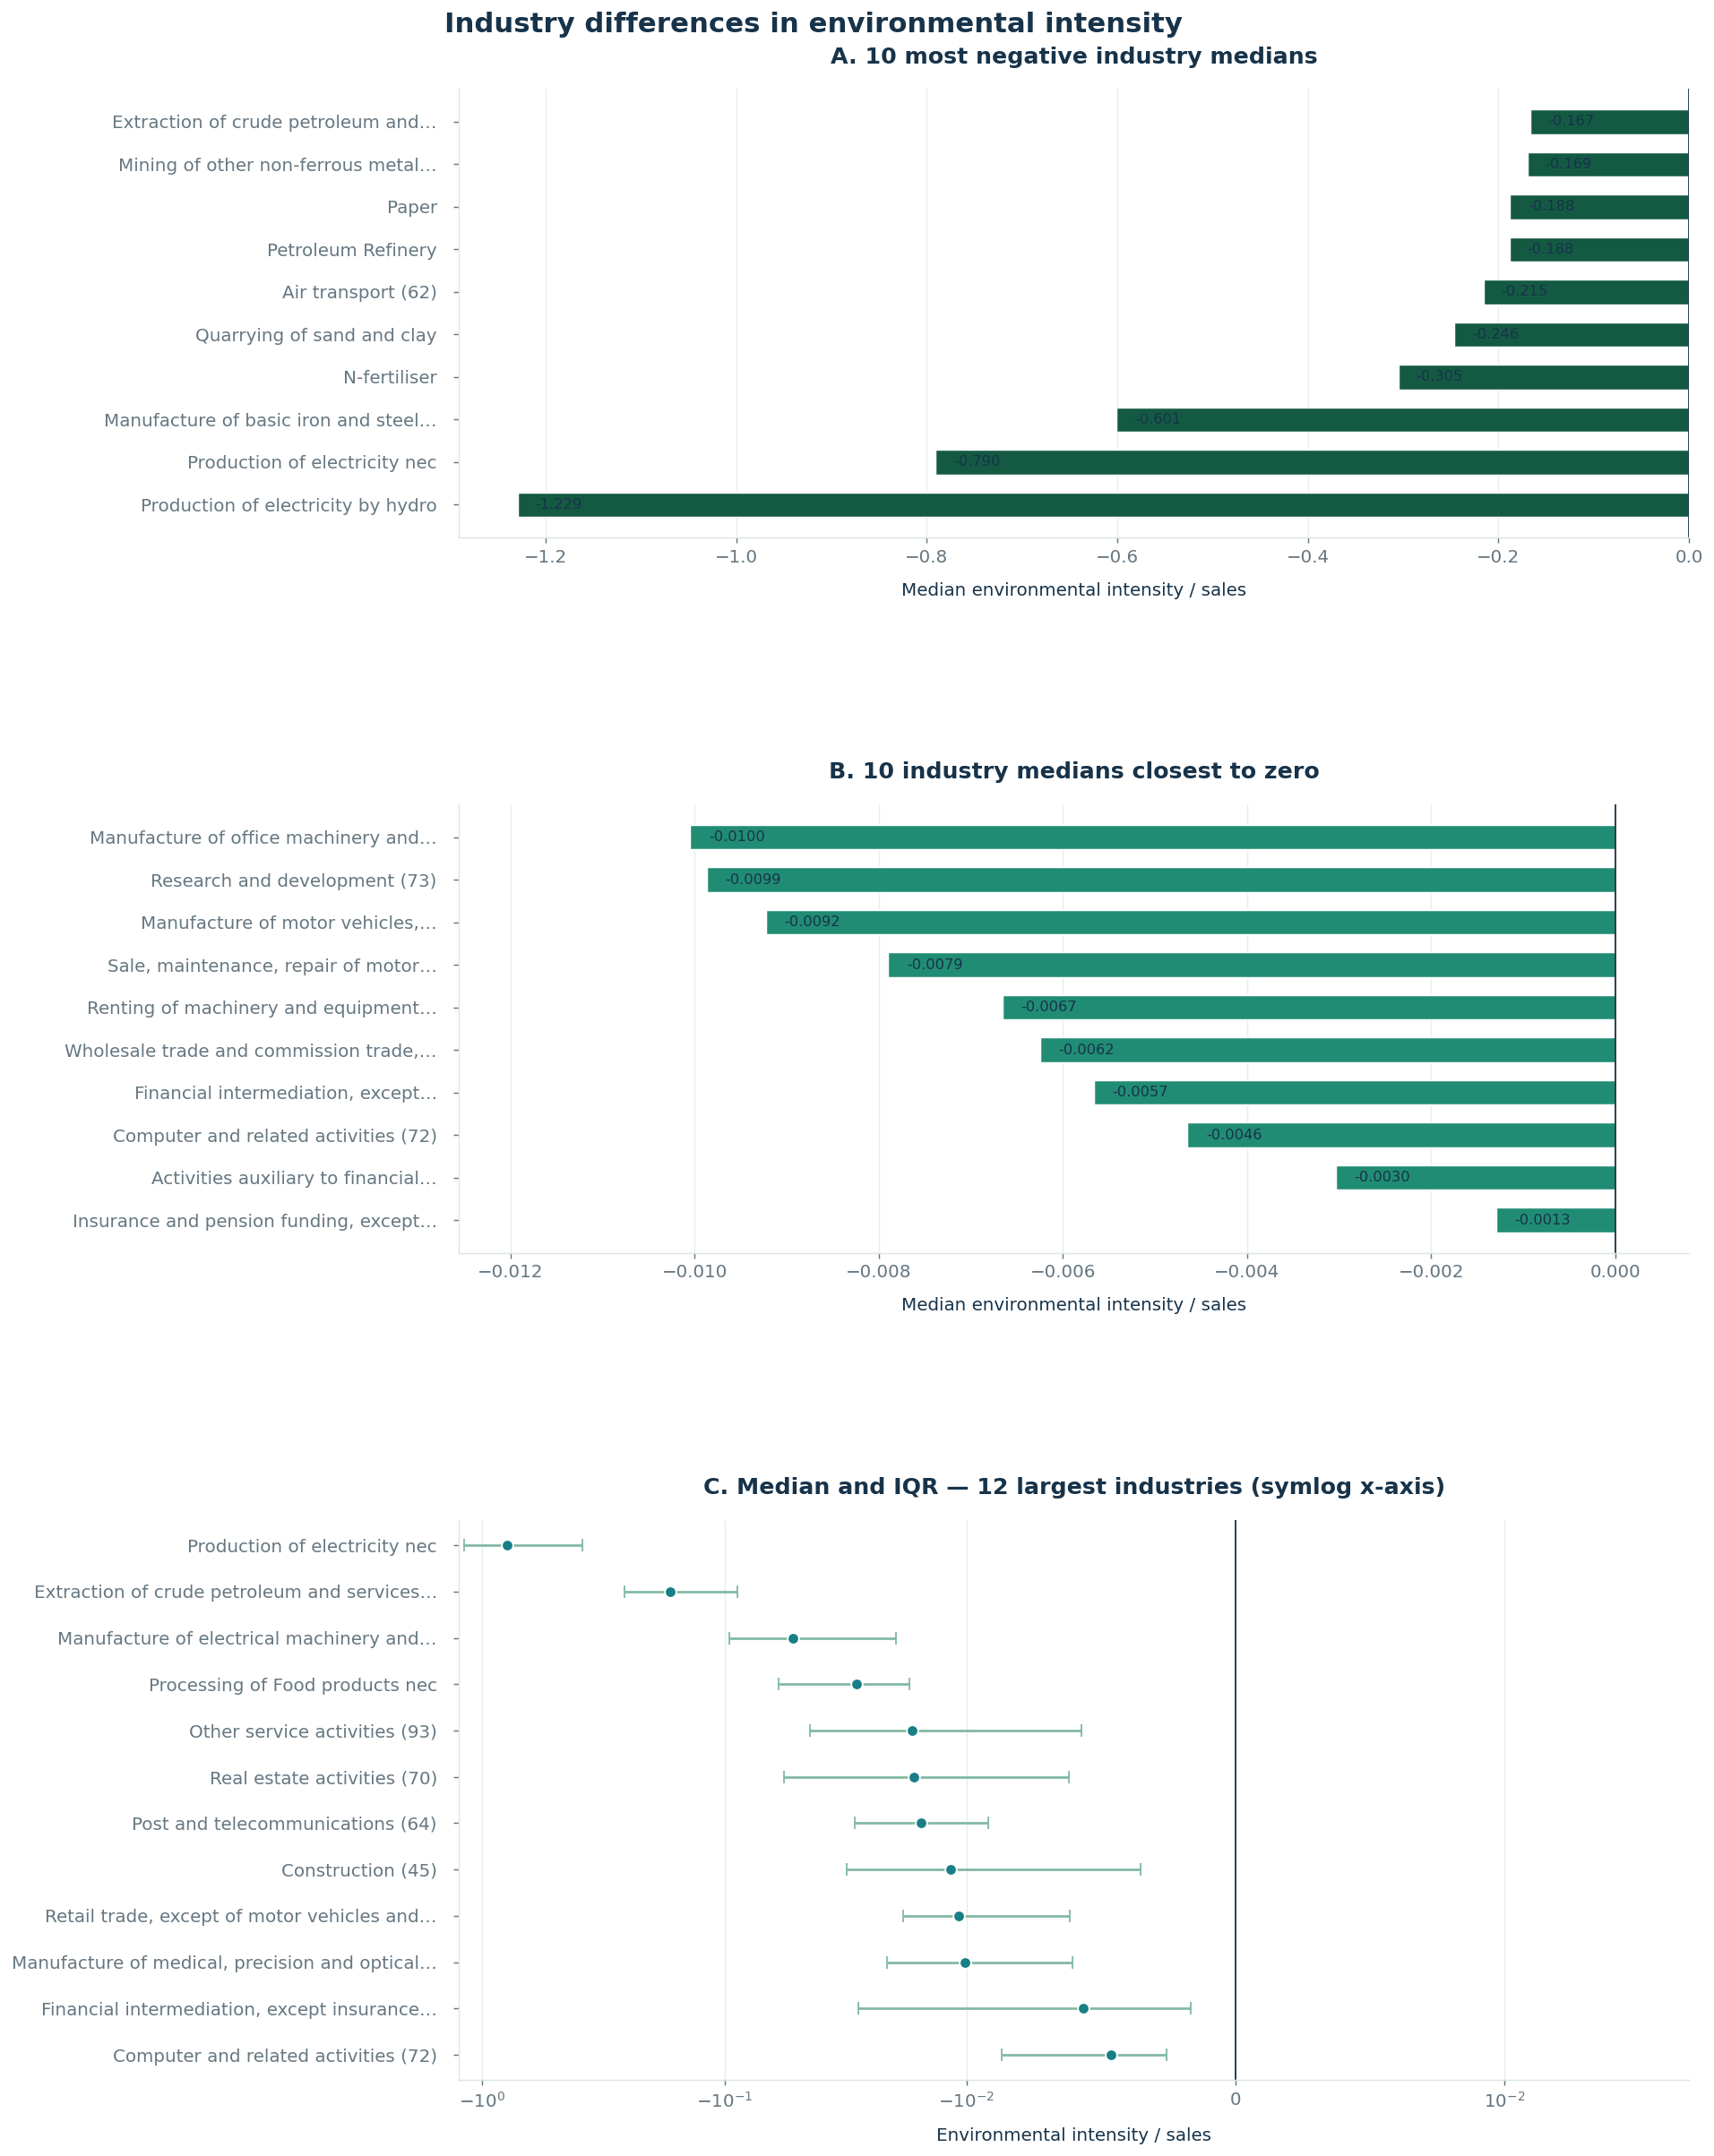

Industry label key


,Chart label,Full industry name
0,Extraction of crude petroleum and services…,Extraction of crude petroleum and services rel...
1,Mining of other non-ferrous metal ores and…,Mining of other non-ferrous metal ores and con...
2,Paper,Paper
3,Petroleum Refinery,Petroleum Refinery
4,Air transport (62),Air transport (62)
5,Quarrying of sand and clay,Quarrying of sand and clay
6,N-fertiliser,N-fertiliser
7,Manufacture of basic iron and steel and of…,Manufacture of basic iron and steel and of fer...
8,Production of electricity nec,Production of electricity nec
9,Production of electricity by hydro,Production of electricity by hydro


In [28]:
MIN_INDUSTRY_N = 30
N_INDUSTRY_EACH_SIDE = 10
TOP_N_INDUSTRIES = 12

def short_label(text, width=36):
    # Single-line label only; no wrapping.
    return textwrap.shorten(
        str(text),
        width=width,
        placeholder="…"
    )

industry_plot = (
    industry_summary[industry_summary["N"] >= MIN_INDUSTRY_N]
    .sort_values("Median")
)

# 10 most negative industries
most_negative_industries = (
    industry_plot.head(N_INDUSTRY_EACH_SIDE)
    .sort_values("Median", ascending=False)
)

# 10 industries closest to zero
least_negative_industries = (
    industry_plot.tail(N_INDUSTRY_EACH_SIDE)
    .sort_values("Median", ascending=True)
)

# 12 largest industries for dispersion view
largest_industries = (
    industry_summary.sort_values("N", ascending=False)
    .head(TOP_N_INDUSTRIES)
    .sort_values("Median")
)

fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 19),
    dpi=130,
    gridspec_kw={"height_ratios": [1, 1, 1.25]}
)

ax_a, ax_b, ax_c = axes

# =========================
# Panel A — 10 most negative
# =========================
a_labels = [short_label(x, 38) for x in most_negative_industries.index]
a_values = most_negative_industries["Median"].values
y_a = np.arange(len(a_labels))

ax_a.barh(
    y_a, a_values,
    height=0.58,
    color=COLORS["forest"],
    edgecolor="white",
    linewidth=0.8
)
ax_a.set_yticks(y_a)
ax_a.set_yticklabels(a_labels, fontsize=11)
ax_a.invert_yaxis()
ax_a.axvline(0, color=COLORS["navy"], linewidth=1)

ax_a.set_title("A. 10 most negative industry medians", fontsize=14, pad=16)
ax_a.set_xlabel("Median environmental intensity / sales", fontsize=11, labelpad=10)
ax_a.tick_params(axis="y", pad=10)

x_span_a = abs(min(a_values.min(), -0.01))
for y_pos, value in zip(y_a, a_values):
    ax_a.text(
        value + 0.015 * x_span_a,
        y_pos,
        f"{value:.3f}",
        va="center",
        ha="left",
        fontsize=9,
        color=COLORS["navy"]
    )

# =========================
# Panel B — 10 closest to zero
# =========================
b_labels = [short_label(x, 38) for x in least_negative_industries.index]
b_values = least_negative_industries["Median"].values
y_b = np.arange(len(b_labels))

ax_b.barh(
    y_b, b_values,
    height=0.58,
    color=COLORS["green"],
    edgecolor="white",
    linewidth=0.8
)
ax_b.set_yticks(y_b)
ax_b.set_yticklabels(b_labels, fontsize=11)
ax_b.invert_yaxis()
ax_b.axvline(0, color=COLORS["navy"], linewidth=1)

ax_b.set_title("B. 10 industry medians closest to zero", fontsize=14, pad=16)
ax_b.set_xlabel("Median environmental intensity / sales", fontsize=11, labelpad=10)
ax_b.tick_params(axis="y", pad=10)

min_b = min(b_values.min() * 1.25, -0.005)
ax_b.set_xlim(min_b, 0.0008)

for y_pos, value in zip(y_b, b_values):
    ax_b.text(
        value + 0.00020,
        y_pos,
        f"{value:.4f}",
        va="center",
        ha="left",
        fontsize=9,
        color=COLORS["navy"]
    )

# =========================
# Panel C — largest industries
# =========================
c_labels = [short_label(x, 46) for x in largest_industries.index]
y_c = np.arange(len(c_labels))

median = largest_industries["Median"].values
lower = median - largest_industries["P25"].values
upper = largest_industries["P75"].values - median

ax_c.errorbar(
    median,
    y_c,
    xerr=[lower, upper],
    fmt="o",
    color=COLORS["teal"],
    ecolor=COLORS["sage"],
    markerfacecolor=COLORS["teal"],
    markeredgecolor="white",
    capsize=4,
    elinewidth=1.5,
    markersize=7
)

ax_c.set_yticks(y_c)
ax_c.set_yticklabels(c_labels, fontsize=11)
ax_c.invert_yaxis()
ax_c.set_xscale("symlog", linthresh=0.01)
ax_c.axvline(0, color=COLORS["navy"], linewidth=1)

ax_c.set_title(
    f"C. Median and IQR — {TOP_N_INDUSTRIES} largest industries (symlog x-axis)",
    fontsize=14,
    pad=16
)
ax_c.set_xlabel("Environmental intensity / sales", fontsize=11, labelpad=10)
ax_c.tick_params(axis="y", pad=10)

for ax in axes:
    ax.grid(axis="x", color=COLORS["grid"], linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Industry differences in environmental intensity",
    fontsize=17,
    fontweight="bold",
    color=COLORS["navy"],
    y=0.985
)

plt.subplots_adjust(
    left=0.31,
    right=0.97,
    top=0.95,
    bottom=0.05,
    hspace=0.55
)

plt.show()

all_plotted_industries = list(dict.fromkeys(
    list(most_negative_industries.index)
    + list(least_negative_industries.index)
    + list(largest_industries.index)
))

industry_label_key = pd.DataFrame({
    "Chart label": [short_label(x, 46) for x in all_plotted_industries],
    "Full industry name": all_plotted_industries
})

print("Industry label key")
display(industry_label_key)


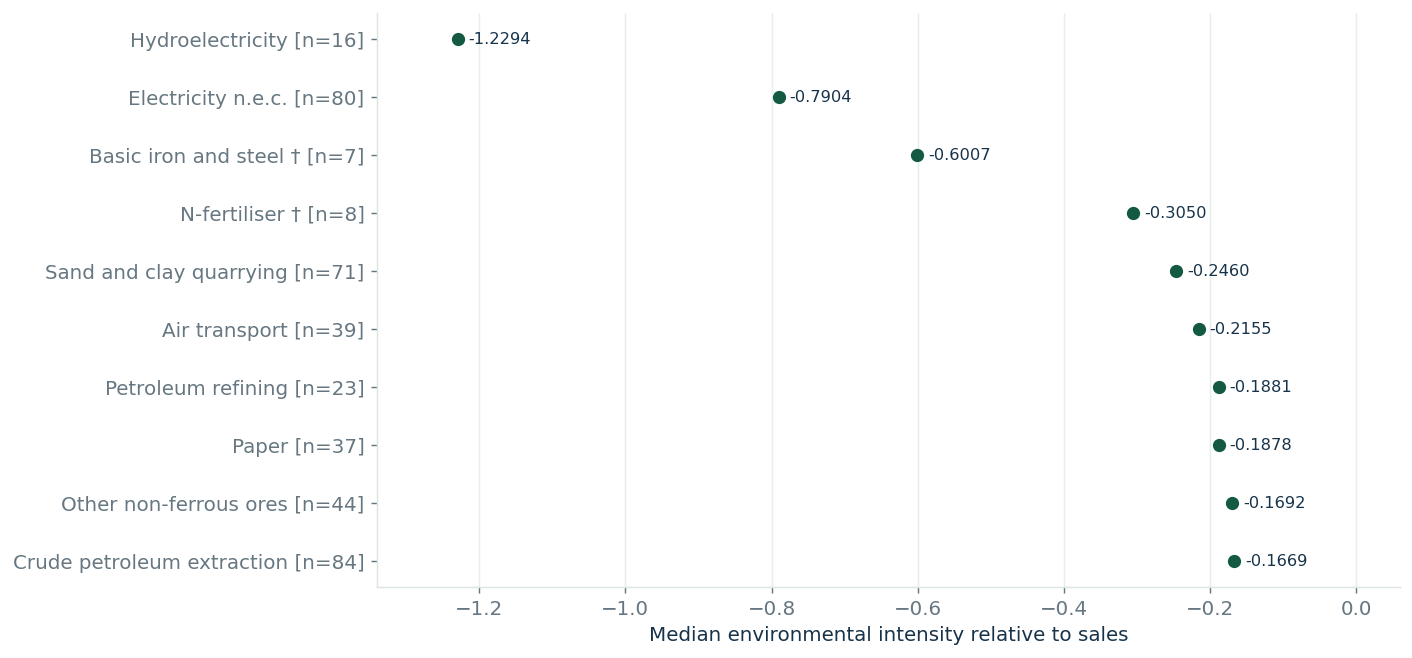

In [ ]:
# PDF Figure 1: Ten most negative eligible industry medians
# Bracketed n counts unique companies; the dagger flags fewer than 10.
def plot_pdf_industry_medians():
    chart_data = industry_summary.loc[industry_summary["N"] >= 30].sort_values("Median").head(10)
    company_counts = df.groupby(INDUSTRY)[COMPANY].nunique()
    abbreviations = {
        "Production of electricity by hydro": "Hydroelectricity",
        "Production of electricity nec": "Electricity n.e.c.",
        "Manufacture of basic iron and steel and of ferro-alloys and first products thereof": "Basic iron and steel",
        "N-fertiliser": "N-fertiliser",
        "Quarrying of sand and clay": "Sand and clay quarrying",
        "Air transport (62)": "Air transport",
        "Petroleum Refinery": "Petroleum refining",
        "Paper": "Paper",
        "Mining of other non-ferrous metal ores and concentrates": "Other non-ferrous ores",
        "Extraction of crude petroleum and services related to crude oil extraction, excluding surveying": "Crude petroleum extraction",
    }
    labels = [
        f"{abbreviations.get(name, name)}{' †' if company_counts[name] < 10 else ''} [n={company_counts[name]}]"
        for name in chart_data.index
    ]
    fig, ax = plt.subplots(figsize=(11, 5.2))
    y = np.arange(len(chart_data))
    ax.scatter(chart_data["Median"], y, color=COLORS["forest"], s=40, zorder=3)
    for position, value in zip(y, chart_data["Median"]):
        ax.annotate(f"{value:.4f}", (value, position), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set_xlim(chart_data["Median"].min() - 0.11, 0.06)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(0.2))
    ax.set_xlabel("Median environmental intensity relative to sales")
    ax.grid(axis="x", color=COLORS["grid"], linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()

plot_pdf_industry_medians()


## 1.2 Statistical test — industry

The Kruskal–Wallis test evaluates whether environmental-intensity distributions differ across the sufficiently represented industries.

- **H₀:** the distributions are the same across industries.
- **H₁:** at least one industry differs.

The test output also reports how much of the full dataset is retained after the **N≥30 firm-year observation rule**. This threshold is based on observations, not unique companies.


### Industry omnibus comparison

Because repeated firm-year observations weaken the strict independence assumption, statistical significance is interpreted together with **eta-squared H**, the descriptive distributions, and the company-level robustness check below.


In [29]:
industry_test = kruskal_with_eta_h(
    df,
    group_col=INDUSTRY,
    min_n=MIN_INDUSTRY_N
)

industry_test["Effect size interpretation"] = eta_effect_label(
    industry_test["Eta-squared H"]
)

industry_display = industry_test.copy()
industry_display["p-value"] = format_p(industry_display["p-value"])
display(pd.Series(industry_display).to_frame("Industry comparison"))


,Industry comparison
Groups total,56
Groups tested,47
Groups excluded,9
N total,14015
N tested,13919
N excluded,96
H,"6,264.012491"
p-value,< .001
Eta-squared H,0.448242
Effect size interpretation,Large


### Industry interpretation

With the **N≥30 firm-year observation rule**, **47 of 56 industries** are included in the inferential comparison, covering **13,919 of 14,015 observations (99.3%)**. Nine industries and 96 observations are excluded from the Kruskal–Wallis test because of small group size, but they remain in the full descriptive table.

Because the threshold is based on **firm-year observations rather than unique companies**, an eligible industry may still contain fewer than 30 distinct firms. The descriptive table therefore reports both `N` and `Companies`.

Interpret the result using the median ranking, within-industry IQR, eta-squared H effect size, and the p-value only as supporting evidence because repeated company observations can make it overly small.


## 1.3 Robustness — one observation per company

The main industry test uses firm-year observations, so companies with more observed years contribute more rows. As a robustness check, each company is reduced to **one median Environmental Intensity (Sales)** value across its observed years.

The comparison keeps the same industries that meet the main **N≥30 firm-year** rule. If the industry effect remains large, the main conclusion is not being driven only by repeated observations from the same firms.


In [30]:
eligible_industries_main = (
    df[INDUSTRY].value_counts()
      .loc[lambda s: s >= MIN_INDUSTRY_N]
      .index
)

firm_industry = (
    df[df[INDUSTRY].isin(eligible_industries_main)]
    .groupby(COMPANY)
    .agg(
        firm_median_intensity=(INTENSITY, "median"),
        industry=(INDUSTRY, "first"),
    )
    .dropna()
)

firm_groups = [
    g["firm_median_intensity"].values
    for _, g in firm_industry.groupby("industry")
]

firm_H, firm_p = kruskal(*firm_groups)
firm_k = len(firm_groups)
firm_n = len(firm_industry)
firm_eta_h = (firm_H - firm_k + 1) / (firm_n - firm_k)

firm_level_industry_test = pd.Series({
    "Industries tested": firm_k,
    "Companies": firm_n,
    "Kruskal–Wallis H": firm_H,
    "p-value": format_p(firm_p),
    "Eta-squared H": firm_eta_h,
    "Interpretation": eta_effect_label(firm_eta_h),
})

display(firm_level_industry_test.to_frame("Company-level industry robustness"))


,Company-level industry robustness
Industries tested,47
Companies,2457
Kruskal–Wallis H,"1,084.823970"
p-value,< .001
Eta-squared H,0.431047
Interpretation,Large


# 2. Country differences

This section asks:

> **Does environmental intensity relative to sales differ across countries?**

Country comparisons are particularly sensitive to sample size because some countries contain very few company-year observations.

Therefore:

- the full descriptive table is retained;
- charts and inferential testing use a minimum sample threshold.

Default threshold:

- **at least 30 observations per country**


In [31]:
country_summary = grouped_summary(df, COUNTRY)

print(f"Total countries in descriptive table: {len(country_summary)}")
display(country_summary)


Total countries in descriptive table: 68


,N,Companies,Mean,Median,Std,P25,P75,IQR
country,,,,,,,,
BAHRAIN,1,1,-1.461412,-1.461412,NaN,-1.461412,-1.461412,0.000000
CZECHIA,10,2,-0.803265,-0.850557,0.297862,-0.979814,-0.800030,0.179783
SAUDI ARABIA,5,2,-0.757092,-0.832734,0.335581,-0.852545,-0.832164,0.020381
PAKISTAN,6,1,-0.302315,-0.294222,0.057780,-0.340060,-0.260259,0.079801
VIRGIN ISLANDS (BRITISH),9,1,-0.290542,-0.293493,0.089504,-0.318707,-0.254455,0.064252
...,...,...,...,...,...,...,...,...
GREECE,36,6,-0.121707,-0.005953,0.356421,-0.023354,-0.004308,0.019046
JERSEY,31,7,-0.028887,-0.004686,0.084096,-0.020097,-0.000600,0.019497
DENMARK,71,14,-0.018340,-0.003591,0.064062,-0.024242,-0.000544,0.023698


## 2.1 Country distribution — multi-panel view

The figure combines:

- **Panel A:** countries at the two ends of the median-intensity ranking among groups with at least 30 firm-year observations;
- **Panel B:** median and IQR for the 15 largest countries by observation count.

This keeps small-country samples from dominating the visual conclusions.


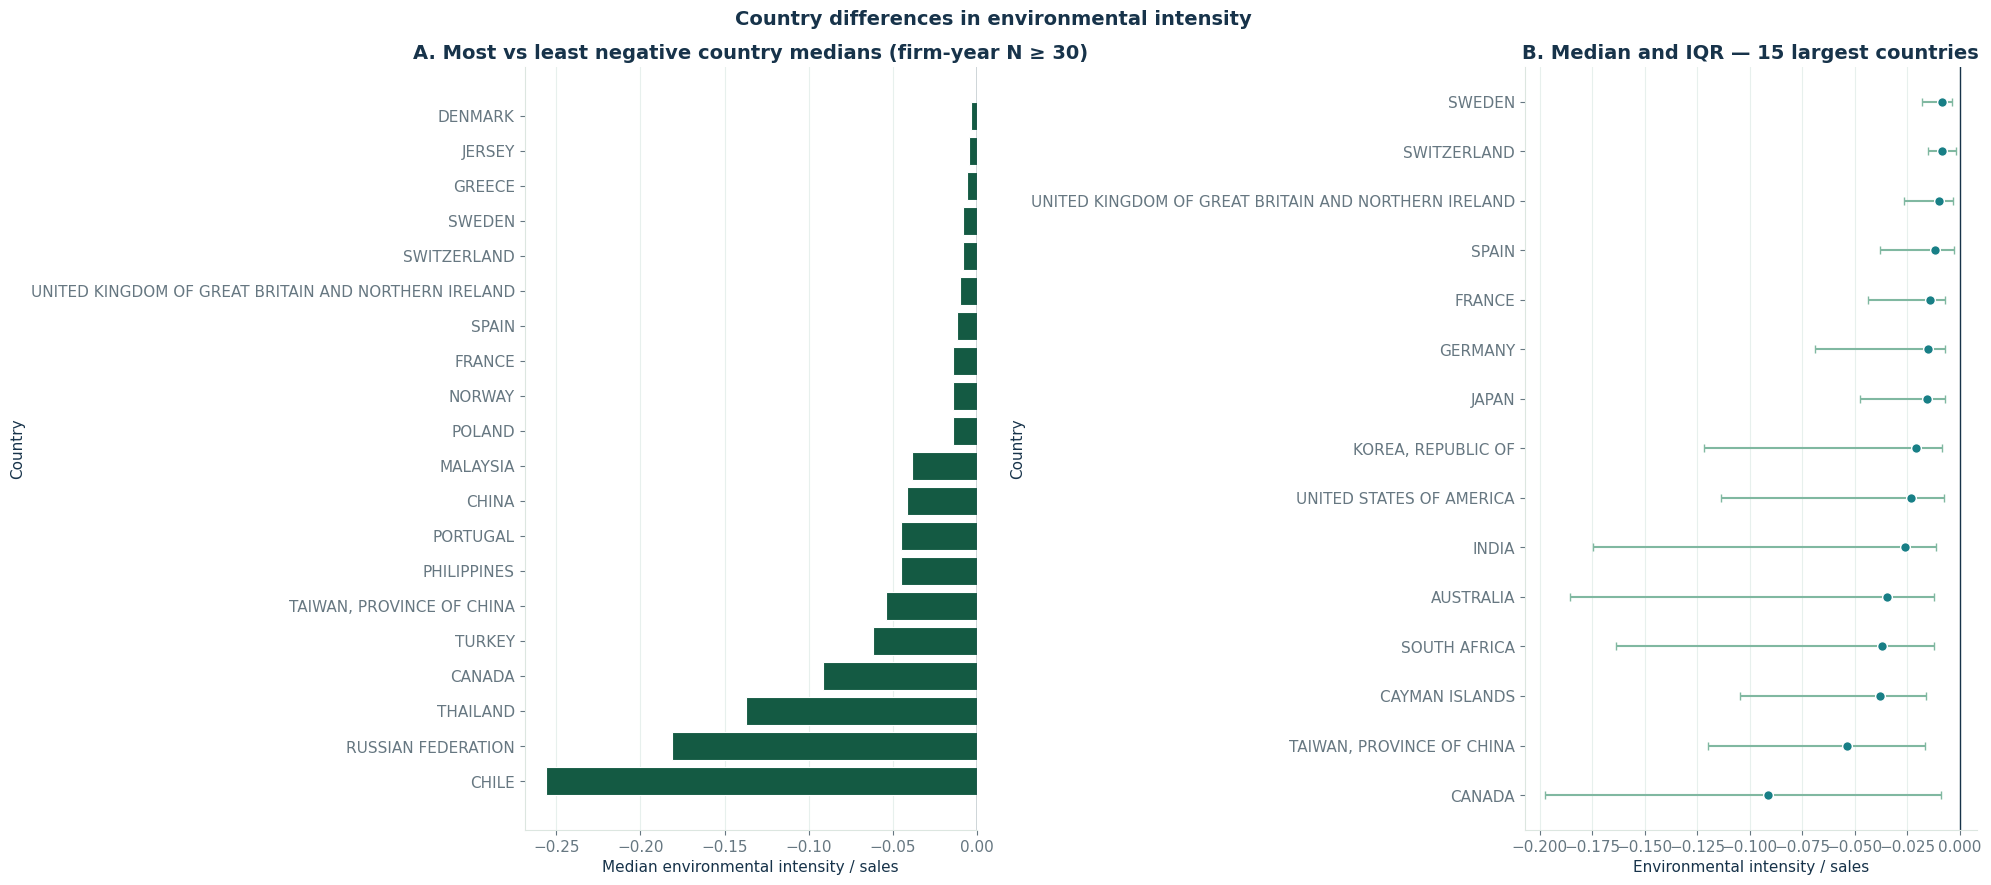

In [32]:
MIN_COUNTRY_N = 30
N_EACH_SIDE = 10
TOP_N_COUNTRIES = 15

eligible_countries = (
    country_summary[country_summary["N"] >= MIN_COUNTRY_N]
    .sort_values("Median")
)

country_extremes = pd.concat([
    eligible_countries.head(N_EACH_SIDE),
    eligible_countries.tail(N_EACH_SIDE)
]).drop_duplicates().sort_values("Median")

largest_countries = (
    country_summary.sort_values("N", ascending=False)
    .head(TOP_N_COUNTRIES)
    .sort_values("Median")
)

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

# Panel A — extremes
axes[0].barh(
    country_extremes.index,
    country_extremes["Median"],
    color=COLORS["forest"],
    edgecolor="white",
    linewidth=0.8
)
axes[0].axvline(0, color=COLORS["navy"], linewidth=1)
axes[0].set_title(
    f"A. Most vs least negative country medians (firm-year N ≥ {MIN_COUNTRY_N})"
)
axes[0].set_xlabel("Median environmental intensity / sales")
axes[0].set_ylabel("Country")

# Panel B — largest countries with IQR
y = np.arange(len(largest_countries))
median = largest_countries["Median"].values
lower = median - largest_countries["P25"].values
upper = largest_countries["P75"].values - median

axes[1].errorbar(
    median,
    y,
    xerr=[lower, upper],
    fmt="o",
    color=COLORS["teal"],
    ecolor=COLORS["sage"],
    markerfacecolor=COLORS["teal"],
    markeredgecolor="white",
    capsize=3,
    elinewidth=1.5,
    markersize=7
)
axes[1].set_yticks(y)
axes[1].set_yticklabels(largest_countries.index)
axes[1].axvline(0, color=COLORS["navy"], linewidth=1)
axes[1].set_title(f"B. Median and IQR — {TOP_N_COUNTRIES} largest countries")
axes[1].set_xlabel("Environmental intensity / sales")
axes[1].set_ylabel("Country")

for ax in axes:
    ax.grid(axis="x", color=COLORS["grid"], linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Country differences in environmental intensity",
    fontsize=14,
    fontweight="bold",
    color=COLORS["navy"]
)
plt.tight_layout()
plt.show()


## 2.2 Statistical test — country

The Kruskal–Wallis test evaluates whether environmental-intensity distributions differ across sufficiently represented countries.

- **H₀:** the distributions are the same across countries.
- **H₁:** at least one country differs.

The output explicitly reports the groups and observations retained and excluded by the **N≥30 firm-year observation rule**. This threshold is based on observations, not unique companies.


### Country omnibus comparison

Country differences are interpreted as **descriptive associations**, not isolated geographic effects. Industry composition may contribute to cross-country differences; this analysis does not attempt to disentangle country-specific effects from industry effects.

In [33]:
country_test = kruskal_with_eta_h(
    df,
    group_col=COUNTRY,
    min_n=MIN_COUNTRY_N
)

country_test["Effect size interpretation"] = eta_effect_label(
    country_test["Eta-squared H"]
)

country_display = country_test.copy()
country_display["p-value"] = format_p(country_display["p-value"])
display(pd.Series(country_display).to_frame("Country comparison"))


,Country comparison
Groups total,68
Groups tested,40
Groups excluded,28
N total,14015
N tested,13753
N excluded,262
H,"1,331.605734"
p-value,< .001
Eta-squared H,0.094261
Effect size interpretation,Moderate


### Country interpretation

With the **N≥30 firm-year observation rule**, **40 of 68 countries** are included in the inferential comparison, covering **13,753 of 14,015 observations (98.1%)**. Twenty-eight countries and 262 observations are excluded from the Kruskal–Wallis test because of small group size, while remaining visible in the descriptive table.

The threshold refers to **firm-year observations rather than unique firms**. Therefore, some eligible countries are still represented by relatively few companies—for example, Chile has 40 firm-year observations from 9 companies, Jersey has 31 from 7 companies, and Greece has 36 from 6 companies.

Interpret the result cautiously:

1. emphasize effect size rather than p-value alone because repeated firms weaken independence;
2. treat country rankings as descriptive rather than definitive when the number of unique firms is small;
3. do not attribute the country effect only to industry mix. Country differences may reflect both industry composition and country-specific factors, and the present analysis does not disentangle them.


# 3. Temporal differences

A simple yearly trend can be misleading in an **unbalanced panel** because the set of companies observed changes over time.

Temporal analysis is therefore separated into three layers:

1. **Full sample:** What does the observed sample look like each year?
2. **Balanced panel:** What happens when we hold the set of companies constant?
3. **Within-company change:** Do individual companies move toward higher or lower environmental intensity from one consecutive year to the next?


# 3.1 Full-sample temporal pattern

This section calculates yearly descriptive statistics for all available company–year observations.

The yearly median intensity, its interquartile range (IQR), and the number of companies represented are incorporated into the consolidated temporal figure (Figure 3, Panels A–B).

In [34]:
year_summary = (
    df.groupby(YEAR)
      .agg(
          N=(INTENSITY, "count"),
          Companies=(COMPANY, "nunique"),
          Mean=(INTENSITY, "mean"),
          Median=(INTENSITY, "median"),
          Std=(INTENSITY, "std"),
          P25=(INTENSITY, lambda x: x.quantile(0.25)),
          P75=(INTENSITY, lambda x: x.quantile(0.75)),
      )
)

year_summary["IQR"] = year_summary["P75"] - year_summary["P25"]

display(year_summary)


,N,Companies,Mean,Median,Std,P25,P75,IQR
year,,,,,,,,
2010,1003,1003,-0.094204,-0.016436,0.259651,-0.075174,-0.006008,0.069166
2011,1061,1061,-0.101129,-0.017165,0.266831,-0.075592,-0.006502,0.069090
2012,1206,1206,-0.105156,-0.017323,0.274502,-0.077572,-0.006177,0.071395
2013,1323,1323,-0.106618,-0.018847,0.256606,-0.084135,-0.007170,0.076965
2014,1413,1413,-0.106430,-0.020863,0.240170,-0.087453,-0.007383,0.080069
2015,1466,1466,-0.117939,-0.021437,0.261810,-0.097270,-0.007233,0.090037
2016,1612,1612,-0.119148,-0.023169,0.272299,-0.101725,-0.007342,0.094382
2017,1653,1653,-0.114218,-0.021142,0.274205,-0.097120,-0.007190,0.089929
2018,1615,1615,-0.112593,-0.021855,0.266408,-0.099040,-0.006784,0.092256


In [35]:
# The full-sample temporal statistics are visualized together with the
# balanced-panel comparison and within-company results in the consolidated
# temporal figure in the final plotting cell of Section 3.

## 3.1.1 Full-sample year test

Kruskal–Wallis tests whether the observed environmental-intensity distributions differ across years.

This comparison still combines:

- genuine within-company changes;
- changes in which companies are represented each year.

Because firms recur across years, the Kruskal–Wallis p-value is not a fully independent-sample inference and may be too small. The temporal effect size therefore receives more weight.


In [36]:
year_test = kruskal_with_eta_h(
    df,
    group_col=YEAR,
    min_n=1
)

year_test["Effect size interpretation"] = eta_effect_label(
    year_test["Eta-squared H"]
)

year_display = year_test.copy()
year_display["p-value"] = format_p(year_display["p-value"])
display(pd.Series(year_display).to_frame("Full-sample year comparison"))


,Full-sample year comparison
Groups total,10
Groups tested,10
Groups excluded,0
N total,14015
N tested,14015
N excluded,0
H,32.951377
p-value,< .001
Eta-squared H,0.001710
Effect size interpretation,Negligible


# 3.2 Balanced-panel temporal pattern

A company is included in the balanced panel only if it has an observation in **every year from 2010 to 2019**. This holds the set of companies constant.

The full-sample and balanced-panel median trajectories are compared in **Figure 3, Panel A**. Their yearly company counts are compared in **Figure 3, Panel B**. Both count series use line charts with markers because they represent annual time-series observations; this also keeps the visual encoding consistent.

In [37]:
all_years = sorted(df[YEAR].dropna().unique())
n_years = len(all_years)

company_year_counts = (
    df.groupby(COMPANY)[YEAR]
      .nunique()
)

balanced_companies = company_year_counts[
    company_year_counts == n_years
].index

balanced = df[df[COMPANY].isin(balanced_companies)].copy()

print(f"Years required: {all_years}")
print(f"Number of years: {n_years}")
print(f"Balanced-panel companies: {len(balanced_companies):,}")
print(f"Balanced-panel observations: {len(balanced):,}")


Years required: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
Number of years: 10
Balanced-panel companies: 498
Balanced-panel observations: 4,980


In [38]:
balanced_year_summary = (
    balanced.groupby(YEAR)
            .agg(
                N=(INTENSITY, "count"),
                Companies=(COMPANY, "nunique"),
                Mean=(INTENSITY, "mean"),
                Median=(INTENSITY, "median"),
                P25=(INTENSITY, lambda x: x.quantile(0.25)),
                P75=(INTENSITY, lambda x: x.quantile(0.75)),
            )
)

balanced_year_summary["IQR"] = (
    balanced_year_summary["P75"] - balanced_year_summary["P25"]
)

comparison = pd.DataFrame({
    "Full sample median": year_summary["Median"],
    "Balanced panel median": balanced_year_summary["Median"],
    "Full sample N companies": year_summary["Companies"],
    "Balanced panel N companies": balanced_year_summary["Companies"],
})

display(comparison)


,Full sample median,Balanced panel median,Full sample N companies,Balanced panel N companies
year,,,,
2010,-0.016436,-0.018937,1003,498
2011,-0.017165,-0.018968,1061,498
2012,-0.017323,-0.017870,1206,498
2013,-0.018847,-0.018563,1323,498
2014,-0.020863,-0.020801,1413,498
2015,-0.021437,-0.020253,1466,498
2016,-0.023169,-0.021451,1612,498
2017,-0.021142,-0.019958,1653,498
2018,-0.021855,-0.020038,1615,498


In [39]:
# The full-sample vs. balanced-panel comparison is included in the
# consolidated temporal figure in the final plotting cell of Section 3.

## 3.2.1 Repeated-measures test for the balanced panel

Because the **same companies** are observed in every year, the balanced panel uses the **Friedman test**, a non-parametric repeated-measures test.

- **H₀:** within-company ranks do not differ across years.
- **H₁:** at least one year differs.

Kendall's W is used as the effect-size measure. Because the observed value is close to the conventional 0.10 boundary sometimes used to separate negligible and small effects, the notebook describes it more cautiously as a **weak temporal effect** rather than relying on a rigid categorical label.


In [40]:
balanced_wide = (
    balanced.pivot_table(
        index=COMPANY,
        columns=YEAR,
        values=INTENSITY,
        aggfunc="first"
    )
    .reindex(columns=all_years)
    .dropna()
)

friedman_arrays = [
    balanced_wide[year].values
    for year in all_years
]

friedman_stat, friedman_p = friedmanchisquare(*friedman_arrays)

n_companies_balanced = len(balanced_wide)
k_years = len(all_years)

kendalls_w = (
    friedman_stat / (n_companies_balanced * (k_years - 1))
    if n_companies_balanced > 0 and k_years > 1
    else np.nan
)

balanced_test = pd.Series({
    "Companies": n_companies_balanced,
    "Years": k_years,
    "Friedman chi-square": friedman_stat,
    "p-value": format_p(friedman_p),
    "Kendall's W": kendalls_w,
    "Effect size interpretation": "Weak",
})

display(balanced_test.to_frame("Balanced-panel repeated-measures test"))


,Balanced-panel repeated-measures test
Companies,498
Years,10
Friedman chi-square,433.680175
p-value,< .001
Kendall's W,0.096760
Effect size interpretation,Weak


### Balanced-panel interpretation

The balanced panel contains **498 companies observed in all 10 years (4,980 observations)**.

The full-sample median becomes more negative from about **−0.0164 in 2010 to −0.0227 in 2019**. In contrast, the balanced panel shows **little net endpoint difference** between 2010 (**−0.0189**) and 2019 (**−0.0187**), but it is **not flat throughout the period**. Its median becomes more negative through the mid-2010s, reaches its lowest point around **2016 (−0.0215)**, and then recovers toward its initial level by 2019.

The Friedman test detects differences in within-company ranks across the ten years, while Kendall's W of about **0.097** indicates that the overall temporal effect is **weak**. The sensitivity analysis below checks whether this non-linear pattern is an artifact of restricting the sample to firms observed in all ten years.


## 3.2.2 Sensitivity — how selective is the balanced panel?

The fully balanced panel keeps only firms observed in all ten years. This section checks:

1. **Retention by industry:** whether some industries are much more likely to remain in the balanced panel.
2. **Intensity selection:** whether retained firms have systematically different typical intensity from the remaining firms.
3. **Entry cohorts:** whether firms entering the dataset later have different typical intensity.
4. **Panel-definition sensitivity:** whether the within-firm temporal profile changes when the minimum observation requirement is relaxed from 10 to 8, 6, or 3 years.

Entry cohorts are summarized at the **company level**, so each firm contributes one median intensity rather than being weighted by its number of observed years.

The four panel-definition profiles are visualized together in **Figure 3, Panel C**.

In [41]:
firm = (
    df.groupby(COMPANY)
      .agg(
          n_years=(YEAR, "nunique"),
          first_year=(YEAR, "min"),
          firm_median=(INTENSITY, "median"),
          industry=(INDUSTRY, "first"),
      )
)

firm["balanced"] = firm["n_years"] == n_years

print(f"Retained in 10-year balanced panel: {firm['balanced'].mean():.1%} of firms")

mw = mannwhitneyu(
    firm.loc[firm["balanced"], "firm_median"],
    firm.loc[~firm["balanced"], "firm_median"],
    alternative="two-sided",
)

print(
    "Firm-level median intensity — balanced vs rest: "
    f"{firm.loc[firm['balanced'], 'firm_median'].median():.4f} vs "
    f"{firm.loc[~firm['balanced'], 'firm_median'].median():.4f}; "
    f"Mann–Whitney p = {mw.pvalue:.3f}"
)

top_industries = firm["industry"].value_counts().head(8).index

retention_by_industry = (
    firm[firm["industry"].isin(top_industries)]
    .groupby("industry")["balanced"]
    .agg(["mean", "size"])
    .assign(retained_pct=lambda x: x["mean"] * 100)
    [["size", "retained_pct"]]
    .rename(columns={"size": "Firms", "retained_pct": "% of firms retained"})
    .round(1)
    .sort_values("% of firms retained")
)

display(retention_by_industry)

firm["cohort"] = pd.cut(
    firm["first_year"],
    [2009, 2010, 2013, 2016, 2019],
    labels=["2010", "2011–13", "2014–16", "2017–19"],
)

entry_cohort_summary = (
    firm.groupby("cohort", observed=True)
        .agg(
            Firms=("firm_median", "size"),
            Median_firm_intensity=("firm_median", "median"),
        )
)

display(entry_cohort_summary)

profiles = {}

for min_years in (10, 8, 6, 3):
    keep = firm.index[firm["n_years"] >= min_years]
    subset = df[df[COMPANY].isin(keep)].copy()

    within_firm_deviation = (
        subset[INTENSITY]
        - subset.groupby(COMPANY)[INTENSITY].transform("mean")
    )

    profiles[f">={min_years} yrs (n={len(keep)})"] = (
        within_firm_deviation.groupby(subset[YEAR]).median()
    )

panel_sensitivity = pd.DataFrame(profiles) * 1000
panel_sensitivity.index.name = "Year"

display(panel_sensitivity.round(3).T)


Retained in 10-year balanced panel: 20.0% of firms
Firm-level median intensity — balanced vs rest: -0.0195 vs -0.0226; Mann–Whitney p = 0.703


,Firms,% of firms retained
industry,,
"Financial intermediation, except insurance and pension funding (65)",291,9.600000
Real estate activities (70),130,12.300000
Processing of Food products nec,96,19.800000
"Retail trade, except of motor vehicles and motorcycles; repair of personal and household goods (52)",110,23.600000
Manufacture of electrical machinery and apparatus n.e.c. (31),121,24.800000
Construction (45),107,26.200000
Post and telecommunications (64),92,30.400000
"Manufacture of medical, precision and optical instruments, watches and clocks (33)",94,31.900000


,Firms,Median_firm_intensity
cohort,,
2010,1003,-0.017065
2011–13,540,-0.025411
2014–16,449,-0.029345
2017–19,493,-0.029662


Year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
>=10 yrs (n=498),0.535000,0.989000,1.166000,-0.055000,-0.544000,-1.150000,-1.190000,0.115000,0.441000,0.897000
>=8 yrs (n=907),0.270000,0.598000,1.089000,0.029000,-0.359000,-1.042000,-0.879000,0.221000,0.536000,0.933000
>=6 yrs (n=1259),0.152000,0.535000,0.922000,0.050000,-0.234000,-0.889000,-0.765000,0.189000,0.560000,0.938000
>=3 yrs (n=1878),0.068000,0.428000,0.888000,0.050000,-0.198000,-0.807000,-0.791000,0.184000,0.530000,0.916000


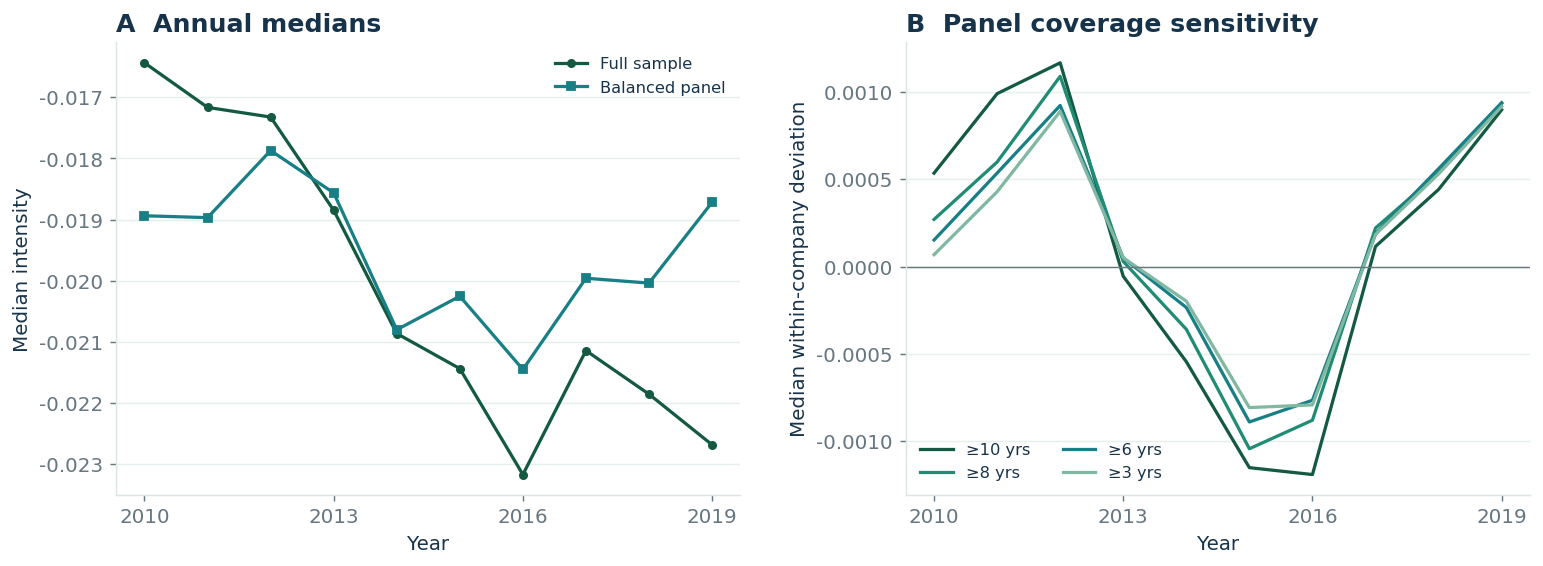

In [ ]:
# PDF Figure 2: Annual medians and panel coverage sensitivity
def plot_pdf_temporal_patterns():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ax_a, ax_b = axes
    ax_a.plot(comparison.index, comparison["Full sample median"],
              color=COLORS["forest"], marker="o", markersize=4,
              linewidth=1.8, label="Full sample")
    ax_a.plot(comparison.index, comparison["Balanced panel median"],
              color=COLORS["teal"], marker="s", markersize=4,
              linewidth=1.8, label="Balanced panel")
    ax_a.set_title("A  Annual medians", loc="left")
    ax_a.set_ylabel("Median intensity")
    ax_a.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.3f"))
    ax_a.legend(frameon=False, fontsize=9)

    # panel_sensitivity is stored in units multiplied by 1,000.
    # Divide back to the original units displayed in the PDF.
    for column, min_years, color in zip(
        panel_sensitivity.columns, (10, 8, 6, 3),
        (COLORS["forest"], COLORS["green"], COLORS["teal"], COLORS["sage"])
    ):
        ax_b.plot(panel_sensitivity.index, panel_sensitivity[column] / 1000,
                  color=color, linewidth=1.8, label=f"≥{min_years} yrs")
    ax_b.axhline(0, color=COLORS["gray"], linewidth=0.8)
    ax_b.set_title("B  Panel coverage sensitivity", loc="left")
    ax_b.set_ylabel("Median within-company deviation")
    ax_b.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.4f"))
    ax_b.legend(frameon=False, fontsize=9, ncol=2, loc="lower left")

    for ax in axes:
        ax.set_xlabel("Year")
        ax.set_xticks([2010, 2013, 2016, 2019])
        ax.grid(axis="y", color=COLORS["grid"], linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout(w_pad=2.5)
    plt.show()

plot_pdf_temporal_patterns()


### Sensitivity interpretation

The ten-year balanced panel retains **20.0% of all firms**, and retention varies substantially across major industries—for example, approximately **9.6%** in financial intermediation, **12.3%** in real estate, and **31.9%** in medical/precision instruments. The balanced panel is therefore selective in terms of **industry representation**.

However, there is **no evidence of systematic selection by typical firm-level intensity**: the balanced and remaining firms have firm-level medians of about **−0.0195** and **−0.0226**, respectively, but the Mann–Whitney test gives **p ≈ 0.70**.

Entry-cohort results show that firms entering the dataset later tend to have more negative typical intensity. At the company level, median intensity is approximately **−0.0171** for firms first observed in 2010, **−0.0254** for 2011–2013 entrants, **−0.0293** for 2014–2016 entrants, and **−0.0297** for 2017–2019 entrants. This supports the interpretation that changing sample composition contributes to the downward trend in the full sample.

Finally, the within-firm temporal profile remains similar when the panel requirement is relaxed from 10 years to 8, 6, and 3 years: all versions deteriorate toward **2015–2016** and recover afterward. The U-shaped pattern is therefore not simply an artifact of selecting the fully balanced panel.


# 3.3 Within-company change

A complementary descriptive approach is to calculate year-to-year change within the same company:

\[
\Delta Intensity_{i,t}
=
Intensity_{i,t}
-
Intensity_{i,t-1}
\]

Only **consecutive-year pairs** are retained. A company observed in 2012 and then again in 2015 is therefore not treated as a one-year change.

### Direction

- `Δ > 0`: environmental intensity becomes less negative / moves upward.
- `Δ < 0`: environmental intensity becomes more negative / moves downward.
- `Δ = 0`: no change.

Given the cost convention in this dataset, a positive change generally means movement toward lower environmental cost intensity.


In [42]:
panel = df[[COMPANY, YEAR, INTENSITY]].copy()
panel = panel.sort_values([COMPANY, YEAR])

panel["previous_year"] = panel.groupby(COMPANY)[YEAR].shift(1)
panel["previous_intensity"] = panel.groupby(COMPANY)[INTENSITY].shift(1)

panel["year_gap"] = panel[YEAR] - panel["previous_year"]
panel["delta_intensity"] = panel[INTENSITY] - panel["previous_intensity"]

# Keep only true consecutive-year pairs
changes = panel[panel["year_gap"] == 1].copy()

changes["direction"] = np.select(
    [
        changes["delta_intensity"] > 0,
        changes["delta_intensity"] < 0,
    ],
    [
        "Less negative / upward",
        "More negative / downward",
    ],
    default="No change"
)

print(f"Consecutive company-year pairs: {len(changes):,}")
print(f"Companies contributing at least one pair: {changes[COMPANY].nunique():,}")


Consecutive company-year pairs: 10,919
Companies contributing at least one pair: 2,042


In [43]:
overall_median_intensity = df[INTENSITY].median()
median_delta = changes["delta_intensity"].median()
relative_delta_pct = abs(median_delta) / abs(overall_median_intensity) * 100

overall_change = pd.Series({
    "Consecutive pairs": len(changes),
    "Companies": changes[COMPANY].nunique(),
    "Mean Δ intensity": changes["delta_intensity"].mean(),
    "Median Δ intensity": median_delta,
    "% Δ > 0": (changes["delta_intensity"] > 0).mean() * 100,
    "% Δ < 0": (changes["delta_intensity"] < 0).mean() * 100,
    "% Δ = 0": (changes["delta_intensity"] == 0).mean() * 100,
    "|Median Δ| as % of |overall median intensity|": relative_delta_pct,
})

display(overall_change.to_frame("Within-company change"))


,Within-company change
Consecutive pairs,"10,919.000000"
Companies,"2,042.000000"
Mean Δ intensity,0.001528
Median Δ intensity,0.000191
% Δ > 0,55.444638
% Δ < 0,44.555362
% Δ = 0,0.000000
|Median Δ| as % of |overall median intensity|,0.943853


## 3.3.1 Year-to-year within-company change

Only true consecutive-year pairs are retained.

The magnitude and direction of annual within-company changes are incorporated into **Figure 3, Panels D–E**:

- **Panel D:** median within-company change by destination year.
- **Panel E:** share of company-year pairs moving upward (`Δ > 0`) versus downward (`Δ < 0`).

These panels complete the consolidated temporal figure, bringing the full-sample trend, balanced-panel comparison, panel-definition sensitivity, and within-company changes together.

In [44]:
change_by_year = (
    changes.groupby(YEAR)
           .agg(
               Pairs=("delta_intensity", "count"),
               Companies=(COMPANY, "nunique"),
               Mean_delta=("delta_intensity", "mean"),
               Median_delta=("delta_intensity", "median"),
               P25_delta=("delta_intensity", lambda x: x.quantile(0.25)),
               P75_delta=("delta_intensity", lambda x: x.quantile(0.75)),
               Positive_share=("delta_intensity", lambda x: (x > 0).mean() * 100),
               Negative_share=("delta_intensity", lambda x: (x < 0).mean() * 100),
               Zero_share=("delta_intensity", lambda x: (x == 0).mean() * 100),
           )
)

display(change_by_year)


,Pairs,Companies,Mean_delta,Median_delta,P25_delta,P75_delta,Positive_share,Negative_share,Zero_share
year,,,,,,,,,
2011,897,897,0.006421,0.000510,-0.000863,0.004546,62.876254,37.123746,0.000000
2012,978,978,0.005725,0.000291,-0.001613,0.003070,56.237219,43.762781,0.000000
2013,1087,1087,-0.009237,-0.000431,-0.004821,0.001185,41.214351,58.785649,0.000000
2014,1223,1223,-0.002876,-0.000503,-0.004424,0.000806,38.920687,61.079313,0.000000
2015,1232,1232,-0.010890,-0.000287,-0.004557,0.000913,42.288961,57.711039,0.000000
2016,1351,1351,0.000943,0.000075,-0.002574,0.001990,52.775722,47.224278,0.000000
2017,1443,1443,0.011167,0.001258,-0.000067,0.007656,73.873874,26.126126,0.000000
2018,1411,1411,0.004628,0.000389,-0.001179,0.003388,61.729270,38.270730,0.000000
2019,1297,1297,0.006463,0.000572,-0.000807,0.003538,65.150347,34.849653,0.000000


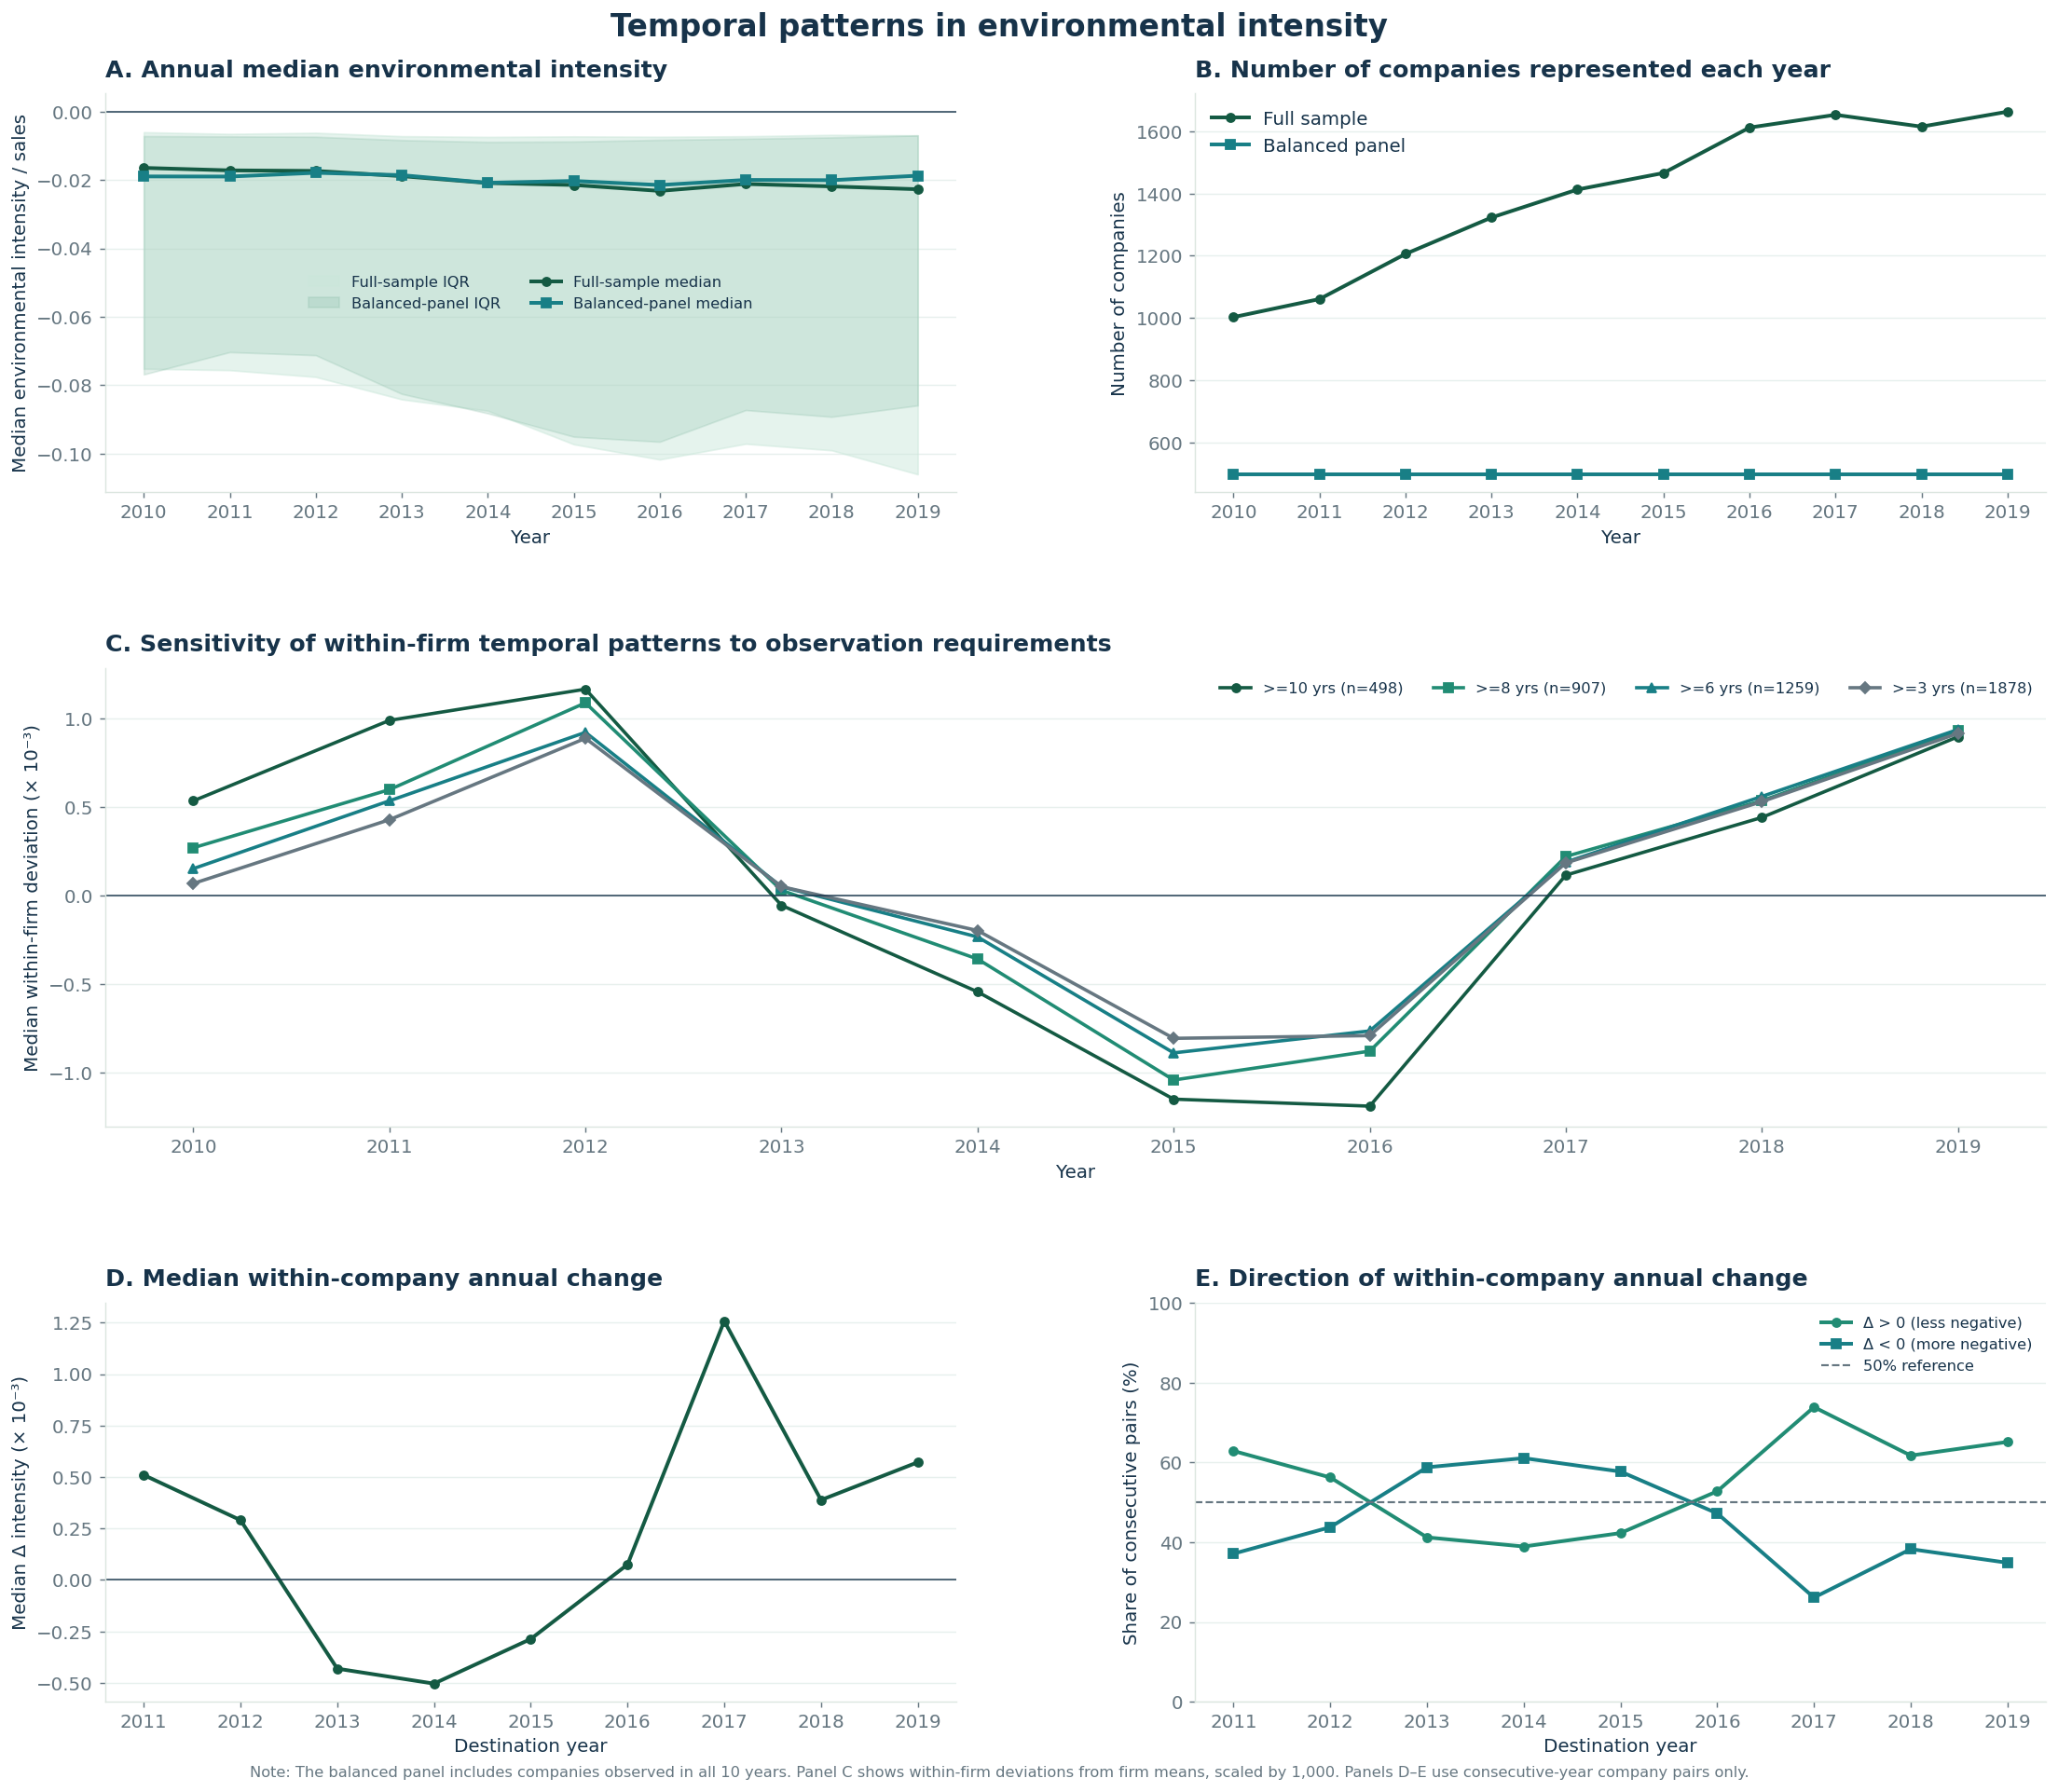

In [45]:
# ============================================================
# Consolidated temporal figure — Sections 3.1 to 3.3
# ============================================================
# Five panels combine:
# A. Full-sample vs balanced-panel median intensity
# B. Number of companies represented each year
# C. Sensitivity to minimum observation requirements (10/8/6/3 years)
# D. Median within-company annual change
# E. Direction of within-company annual change

fig = plt.figure(figsize=(18, 15), dpi=130)
gs = fig.add_gridspec(
    3, 2,
    height_ratios=[1.0, 1.15, 1.0],
    hspace=0.42,
    wspace=0.28
)

ax_a = fig.add_subplot(gs[0, 0])
ax_b = fig.add_subplot(gs[0, 1])
ax_c = fig.add_subplot(gs[1, :])
ax_d = fig.add_subplot(gs[2, 0])
ax_e = fig.add_subplot(gs[2, 1])

# -----------------------------
# Panel A — yearly median intensity
# -----------------------------
years = comparison.index.to_numpy()

ax_a.fill_between(
    years,
    year_summary["P25"].to_numpy(),
    year_summary["P75"].to_numpy(),
    color=COLORS["mint"],
    alpha=0.48,
    label="Full-sample IQR",
    zorder=1
)
ax_a.fill_between(
    years,
    balanced_year_summary["P25"].to_numpy(),
    balanced_year_summary["P75"].to_numpy(),
    color=COLORS["sage"],
    alpha=0.22,
    label="Balanced-panel IQR",
    zorder=1
)
ax_a.plot(
    years,
    comparison["Full sample median"],
    marker="o",
    markersize=5,
    linewidth=2.2,
    color=COLORS["forest"],
    label="Full-sample median",
    zorder=3
)
ax_a.plot(
    years,
    comparison["Balanced panel median"],
    marker="s",
    markersize=5,
    linewidth=2.2,
    color=COLORS["teal"],
    label="Balanced-panel median",
    zorder=4
)
ax_a.axhline(0, color=COLORS["navy"], linewidth=1, alpha=0.8)
ax_a.set_title("A. Annual median environmental intensity", loc="left", pad=10)
ax_a.set_xlabel("Year")
ax_a.set_ylabel("Median environmental intensity / sales")
ax_a.set_xticks(years)
ax_a.legend(frameon=False, fontsize=9, ncol=2)

# -----------------------------
# Panel B — number of companies by year
# Use line + markers consistently for annual count series.
# -----------------------------
ax_b.plot(
    years,
    comparison["Full sample N companies"],
    marker="o",
    markersize=5,
    linewidth=2.2,
    color=COLORS["forest"],
    label="Full sample"
)
ax_b.plot(
    years,
    comparison["Balanced panel N companies"],
    marker="s",
    markersize=5,
    linewidth=2.2,
    color=COLORS["teal"],
    label="Balanced panel"
)
ax_b.set_title("B. Number of companies represented each year", loc="left", pad=10)
ax_b.set_xlabel("Year")
ax_b.set_ylabel("Number of companies")
ax_b.set_xticks(years)
ax_b.legend(frameon=False)

# -----------------------------
# Panel C — panel-definition sensitivity
# Values are already multiplied by 1,000 in panel_sensitivity.
# -----------------------------
sensitivity_colors = [
    COLORS["forest"],
    COLORS["green"],
    COLORS["teal"],
    COLORS["gray"]
]
sensitivity_markers = ["o", "s", "^", "D"]

for (column, color, marker) in zip(
    panel_sensitivity.columns,
    sensitivity_colors,
    sensitivity_markers
):
    ax_c.plot(
        panel_sensitivity.index,
        panel_sensitivity[column],
        marker=marker,
        markersize=5,
        linewidth=2,
        color=color,
        label=column
    )

ax_c.axhline(0, color=COLORS["navy"], linewidth=1, alpha=0.8)
ax_c.set_title(
    "C. Sensitivity of within-firm temporal patterns to observation requirements",
    loc="left",
    pad=10
)
ax_c.set_xlabel("Year")
ax_c.set_ylabel("Median within-firm deviation (× 10⁻³)")
ax_c.set_xticks(panel_sensitivity.index)
ax_c.legend(frameon=False, ncol=4, fontsize=9)

# -----------------------------
# Panel D — median within-company annual change
# -----------------------------
change_years = change_by_year.index.to_numpy()

ax_d.plot(
    change_years,
    change_by_year["Median_delta"].to_numpy() * 1000,
    marker="o",
    markersize=5,
    linewidth=2.2,
    color=COLORS["forest"]
)
ax_d.axhline(0, color=COLORS["navy"], linewidth=1, alpha=0.8)
ax_d.set_title("D. Median within-company annual change", loc="left", pad=10)
ax_d.set_xlabel("Destination year")
ax_d.set_ylabel("Median Δ intensity (× 10⁻³)")
ax_d.set_xticks(change_years)

# -----------------------------
# Panel E — direction of within-company annual change
# -----------------------------
ax_e.plot(
    change_years,
    change_by_year["Positive_share"],
    marker="o",
    markersize=5,
    linewidth=2.2,
    color=COLORS["green"],
    label="Δ > 0 (less negative)"
)
ax_e.plot(
    change_years,
    change_by_year["Negative_share"],
    marker="s",
    markersize=5,
    linewidth=2.2,
    color=COLORS["teal"],
    label="Δ < 0 (more negative)"
)
ax_e.axhline(
    50,
    color=COLORS["gray"],
    linestyle="--",
    linewidth=1.2,
    label="50% reference"
)
ax_e.set_title("E. Direction of within-company annual change", loc="left", pad=10)
ax_e.set_xlabel("Destination year")
ax_e.set_ylabel("Share of consecutive pairs (%)")
ax_e.set_ylim(0, 100)
ax_e.set_xticks(change_years)
ax_e.legend(frameon=False, fontsize=9)

# -----------------------------
# Consistent styling
# -----------------------------
for ax in [ax_a, ax_b, ax_c, ax_d, ax_e]:
    ax.set_facecolor(COLORS["background"])
    ax.grid(axis="y", color=COLORS["grid"], linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#DCE6E0")
    ax.spines["bottom"].set_color("#DCE6E0")
    ax.tick_params(colors=COLORS["gray"])

fig.suptitle(
    "Temporal patterns in environmental intensity",
    fontsize=18,
    fontweight="bold",
    color=COLORS["navy"],
    y=0.985
)

fig.text(
    0.5, 0.012,
    "Note: The balanced panel includes companies observed in all 10 years. "
    "Panel C shows within-firm deviations from firm means, scaled by 1,000. "
    "Panels D–E use consecutive-year company pairs only.",
    ha="center",
    va="bottom",
    fontsize=9,
    color=COLORS["gray"]
)

plt.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.94,
    bottom=0.055
)
plt.show()


**Figure 3. Temporal Patterns in Environmental Intensity: Full-Sample and Balanced-Panel Trends, Panel-Definition Sensitivity, and Within-Company Annual Changes.** Panels A–B compare annual medians and company counts across the full sample and balanced panel; Panel C assesses sensitivity to minimum observation requirements; Panels D–E summarize the magnitude and direction of consecutive-year within-company changes.

## 3.3.2 Test whether median within-company change differs from zero

The Wilcoxon signed-rank test evaluates whether non-zero consecutive-year changes are centered around zero.

- **H₀:** the distribution of within-company change is centered at zero.
- **H₁:** it is not centered at zero.

A company can contribute several consecutive-year pairs, so pair-level observations are not fully independent. The Wilcoxon p-value is therefore treated as supporting evidence only. The company-cluster bootstrap below provides a robustness interval for the overall share of upward changes.


In [46]:
nonzero_delta = changes.loc[
    changes["delta_intensity"] != 0,
    "delta_intensity"
].dropna()

if len(nonzero_delta) > 0:
    wilcoxon_stat, wilcoxon_p = wilcoxon(
        nonzero_delta,
        alternative="two-sided"
    )
else:
    wilcoxon_stat, wilcoxon_p = np.nan, np.nan

within_test = pd.Series({
    "Non-zero consecutive pairs": len(nonzero_delta),
    "Wilcoxon statistic": wilcoxon_stat,
    "p-value": format_p(wilcoxon_p),
    "Median Δ": changes["delta_intensity"].median(),
})

display(within_test.to_frame("Within-company change test"))


,Within-company change test
Non-zero consecutive pairs,10919
Wilcoxon statistic,"27,321,428.000000"
p-value,< .001
Median Δ,0.000191


## 3.3.3 Company-cluster bootstrap for the upward-change share

Because one company can contribute several consecutive-year pairs, a simple pair-level proportion understates dependence. This check resamples **companies as clusters** and recalculates the overall share of `Δ > 0`.

The bootstrap interval is used as a robustness check for the reported **55.4% upward-change share**.


In [47]:
cluster_change = (
    changes.groupby(COMPANY)
           .agg(
               positive_pairs=("delta_intensity", lambda x: (x > 0).sum()),
               total_pairs=("delta_intensity", "size"),
           )
)

cluster_values = cluster_change[["positive_pairs", "total_pairs"]].to_numpy()

rng = np.random.default_rng(42)
B = 2000
boot_positive_share = np.empty(B)

for b in range(B):
    sampled_idx = rng.integers(
        0,
        len(cluster_values),
        size=len(cluster_values)
    )
    sampled = cluster_values[sampled_idx]

    boot_positive_share[b] = (
        sampled[:, 0].sum()
        / sampled[:, 1].sum()
        * 100
    )

ci_low, ci_high = np.percentile(boot_positive_share, [2.5, 97.5])
observed_positive_share = (changes["delta_intensity"] > 0).mean() * 100

bootstrap_change = pd.Series({
    "Observed % Δ > 0": observed_positive_share,
    "Cluster-bootstrap 95% CI — lower": ci_low,
    "Cluster-bootstrap 95% CI — upper": ci_high,
    "Bootstrap resamples": B,
})

display(bootstrap_change.to_frame("Company-cluster bootstrap"))


,Company-cluster bootstrap
Observed % Δ > 0,55.444638
Cluster-bootstrap 95% CI — lower,54.583598
Cluster-bootstrap 95% CI — upper,56.310872
Bootstrap resamples,"2,000.000000"


# 5. Cross-sectional and temporal findings

The analysis examined how corporate environmental impact intensity differs across **industries, countries, and years**. The evidence shows the strongest distributional differences across industries, weaker differences across countries, and a comparatively weak but non-linear temporal pattern.

### Industry differences

Industry is the clearest source of distributional heterogeneity. Using the N≥30 firm-year observation rule, the test includes **47 of 56 industries and 13,919 of 14,015 observations**. Eta-squared H is approximately **0.448**, indicating a **large industry effect**. A company-level robustness check, in which each firm contributes only one median intensity value, still produces a large industry effect (approximately **0.431** using the same eligible industries), showing that the main conclusion is not driven only by repeated firm-year observations.

### Country differences

Country differences are statistically visible but weaker than industry differences. The N≥30 firm-year observation comparison retains **40 of 68 countries and 13,753 of 14,015 observations**, with eta-squared H of approximately **0.094**, a **moderate** effect. Country rankings should be interpreted cautiously because some eligible countries contain relatively few unique firms. The observed country differences may reflect both **industry composition and country-specific factors**; the analysis does not attempt to separate these mechanisms.

### Temporal differences

The full sample becomes more negative from about **−0.0164 in 2010 to −0.0227 in 2019**, but the full-sample year effect is very small (eta-squared H ≈ **0.0017**). The balanced panel has little net endpoint difference between 2010 and 2019, yet its trajectory is **non-linear rather than flat**: intensity becomes more negative through the mid-2010s, reaches a trough around **2015–2016**, and then recovers toward 2019.

The balanced panel retains only **498 of 2,485 firms (20.0%)**, and retention varies materially across industries. However, the typical firm-level intensity of retained firms is not statistically distinguishable from that of the remaining firms (Mann–Whitney p ≈ **0.70**). Firms entering the dataset in later periods have more negative typical intensity, supporting the interpretation that **changing sample composition contributes to the downward full-sample trend**. Importantly, the same mid-decade trough and later recovery remain visible when the panel requirement is relaxed from 10 years to 8, 6, and 3 years, so the non-linear temporal profile is not simply an artifact of selecting the fully balanced panel.

Across **10,919 consecutive company-year pairs from 2,042 firms**, the median annual change is about **+0.00019**, which is less than **1% of the absolute overall median intensity**. Although **55.4%** of pairs move upward, the direction varies substantially by year; a company-cluster bootstrap places the overall upward-share estimate at roughly **54.6%–56.3%**.

### Overall findings

Corporate environmental impact intensity differs **substantially across industries**, **moderately across countries**, and **weakly but non-linearly over time**. The full-sample temporal decline should not be interpreted as uniform deterioration within firms. Later entrants tend to have more negative intensity, so changing sample composition contributes to the full-sample pattern, while within-firm sensitivity analyses still show a mid-2010s deterioration followed by recovery.

### Inference limitations

1. Firm-year observations repeat companies across time. Company-level and cluster-bootstrap robustness checks reduce, but do not eliminate, dependence concerns.
2. Country differences are descriptive associations. This analysis does not identify whether they arise from industry composition, institutions, regulation, or other country-specific factors.
3. The dataset contains a small share of extreme negative values and positive intensity values. Their substantive interpretation requires the source methodology; The analysis therefore emphasizes robust distributional summaries rather than assigning causes to these observations.


# 6. Compact output table for reporting

This table summarizes the main inferential results. Robustness checks are reported in their respective sections above.


In [48]:
eda_comparison_tests = pd.DataFrame([
    {
        "Dimension": "Industry",
        "Test": "Kruskal–Wallis",
        "Coverage": (
            f"{industry_test['Groups tested']}/{industry_test['Groups total']} groups; "
            f"{industry_test['N tested']:,}/{industry_test['N total']:,} obs"
        ),
        "N excluded": industry_test["N excluded"],
        "Statistic": industry_test["H"],
        "p-value": format_p(industry_test["p-value"]),
        "Effect size": industry_test["Eta-squared H"],
        "Effect metric": "Eta-squared H",
        "Interpretation": industry_test["Effect size interpretation"],
    },
    {
        "Dimension": "Country",
        "Test": "Kruskal–Wallis",
        "Coverage": (
            f"{country_test['Groups tested']}/{country_test['Groups total']} groups; "
            f"{country_test['N tested']:,}/{country_test['N total']:,} obs"
        ),
        "N excluded": country_test["N excluded"],
        "Statistic": country_test["H"],
        "p-value": format_p(country_test["p-value"]),
        "Effect size": country_test["Eta-squared H"],
        "Effect metric": "Eta-squared H",
        "Interpretation": country_test["Effect size interpretation"],
    },
    {
        "Dimension": "Year — full sample",
        "Test": "Kruskal–Wallis",
        "Coverage": (
            f"{year_test['Groups tested']}/{year_test['Groups total']} years; "
            f"{year_test['N tested']:,}/{year_test['N total']:,} obs"
        ),
        "N excluded": year_test["N excluded"],
        "Statistic": year_test["H"],
        "p-value": format_p(year_test["p-value"]),
        "Effect size": year_test["Eta-squared H"],
        "Effect metric": "Eta-squared H",
        "Interpretation": year_test["Effect size interpretation"],
    },
    {
        "Dimension": "Year — balanced panel",
        "Test": "Friedman",
        "Coverage": f"{n_companies_balanced:,} firms × {k_years} years",
        "N excluded": np.nan,
        "Statistic": friedman_stat,
        "p-value": format_p(friedman_p),
        "Effect size": kendalls_w,
        "Effect metric": "Kendall's W",
        "Interpretation": "Weak",
    },
    {
        "Dimension": "Within-company YoY change",
        "Test": "Wilcoxon signed-rank",
        "Coverage": f"{len(nonzero_delta):,} non-zero consecutive pairs",
        "N excluded": np.nan,
        "Statistic": wilcoxon_stat,
        "p-value": format_p(wilcoxon_p),
        "Effect size": np.nan,
        "Effect metric": "—",
        "Interpretation": "Use median Δ and direction shares",
    },
])

display(eda_comparison_tests)


,Dimension,Test,Coverage,N excluded,Statistic,p-value,Effect size,Effect metric,Interpretation
0,Industry,Kruskal–Wallis,"47/56 groups; 13,919/14,015 obs",96.000000,"6,264.012491",< .001,0.448242,Eta-squared H,Large
1,Country,Kruskal–Wallis,"40/68 groups; 13,753/14,015 obs",262.000000,"1,331.605734",< .001,0.094261,Eta-squared H,Moderate
2,Year — full sample,Kruskal–Wallis,"10/10 years; 14,015/14,015 obs",0.000000,32.951377,< .001,0.001710,Eta-squared H,Negligible
3,Year — balanced panel,Friedman,498 firms × 10 years,NaN,433.680175,< .001,0.096760,Kendall's W,Weak
4,Within-company YoY change,Wilcoxon signed-rank,"10,919 non-zero consecutive pairs",NaN,"27,321,428.000000",< .001,NaN,—,Use median Δ and direction shares


# 7. Publication-ready multi-panel figures

The following two figures consolidate the detailed exploratory charts into report-ready multi-panel figures. Each figure communicates one overarching finding; panels (a)–(d) provide complementary evidence in a logical reading order. The existing individual charts remain available above for detailed inspection.

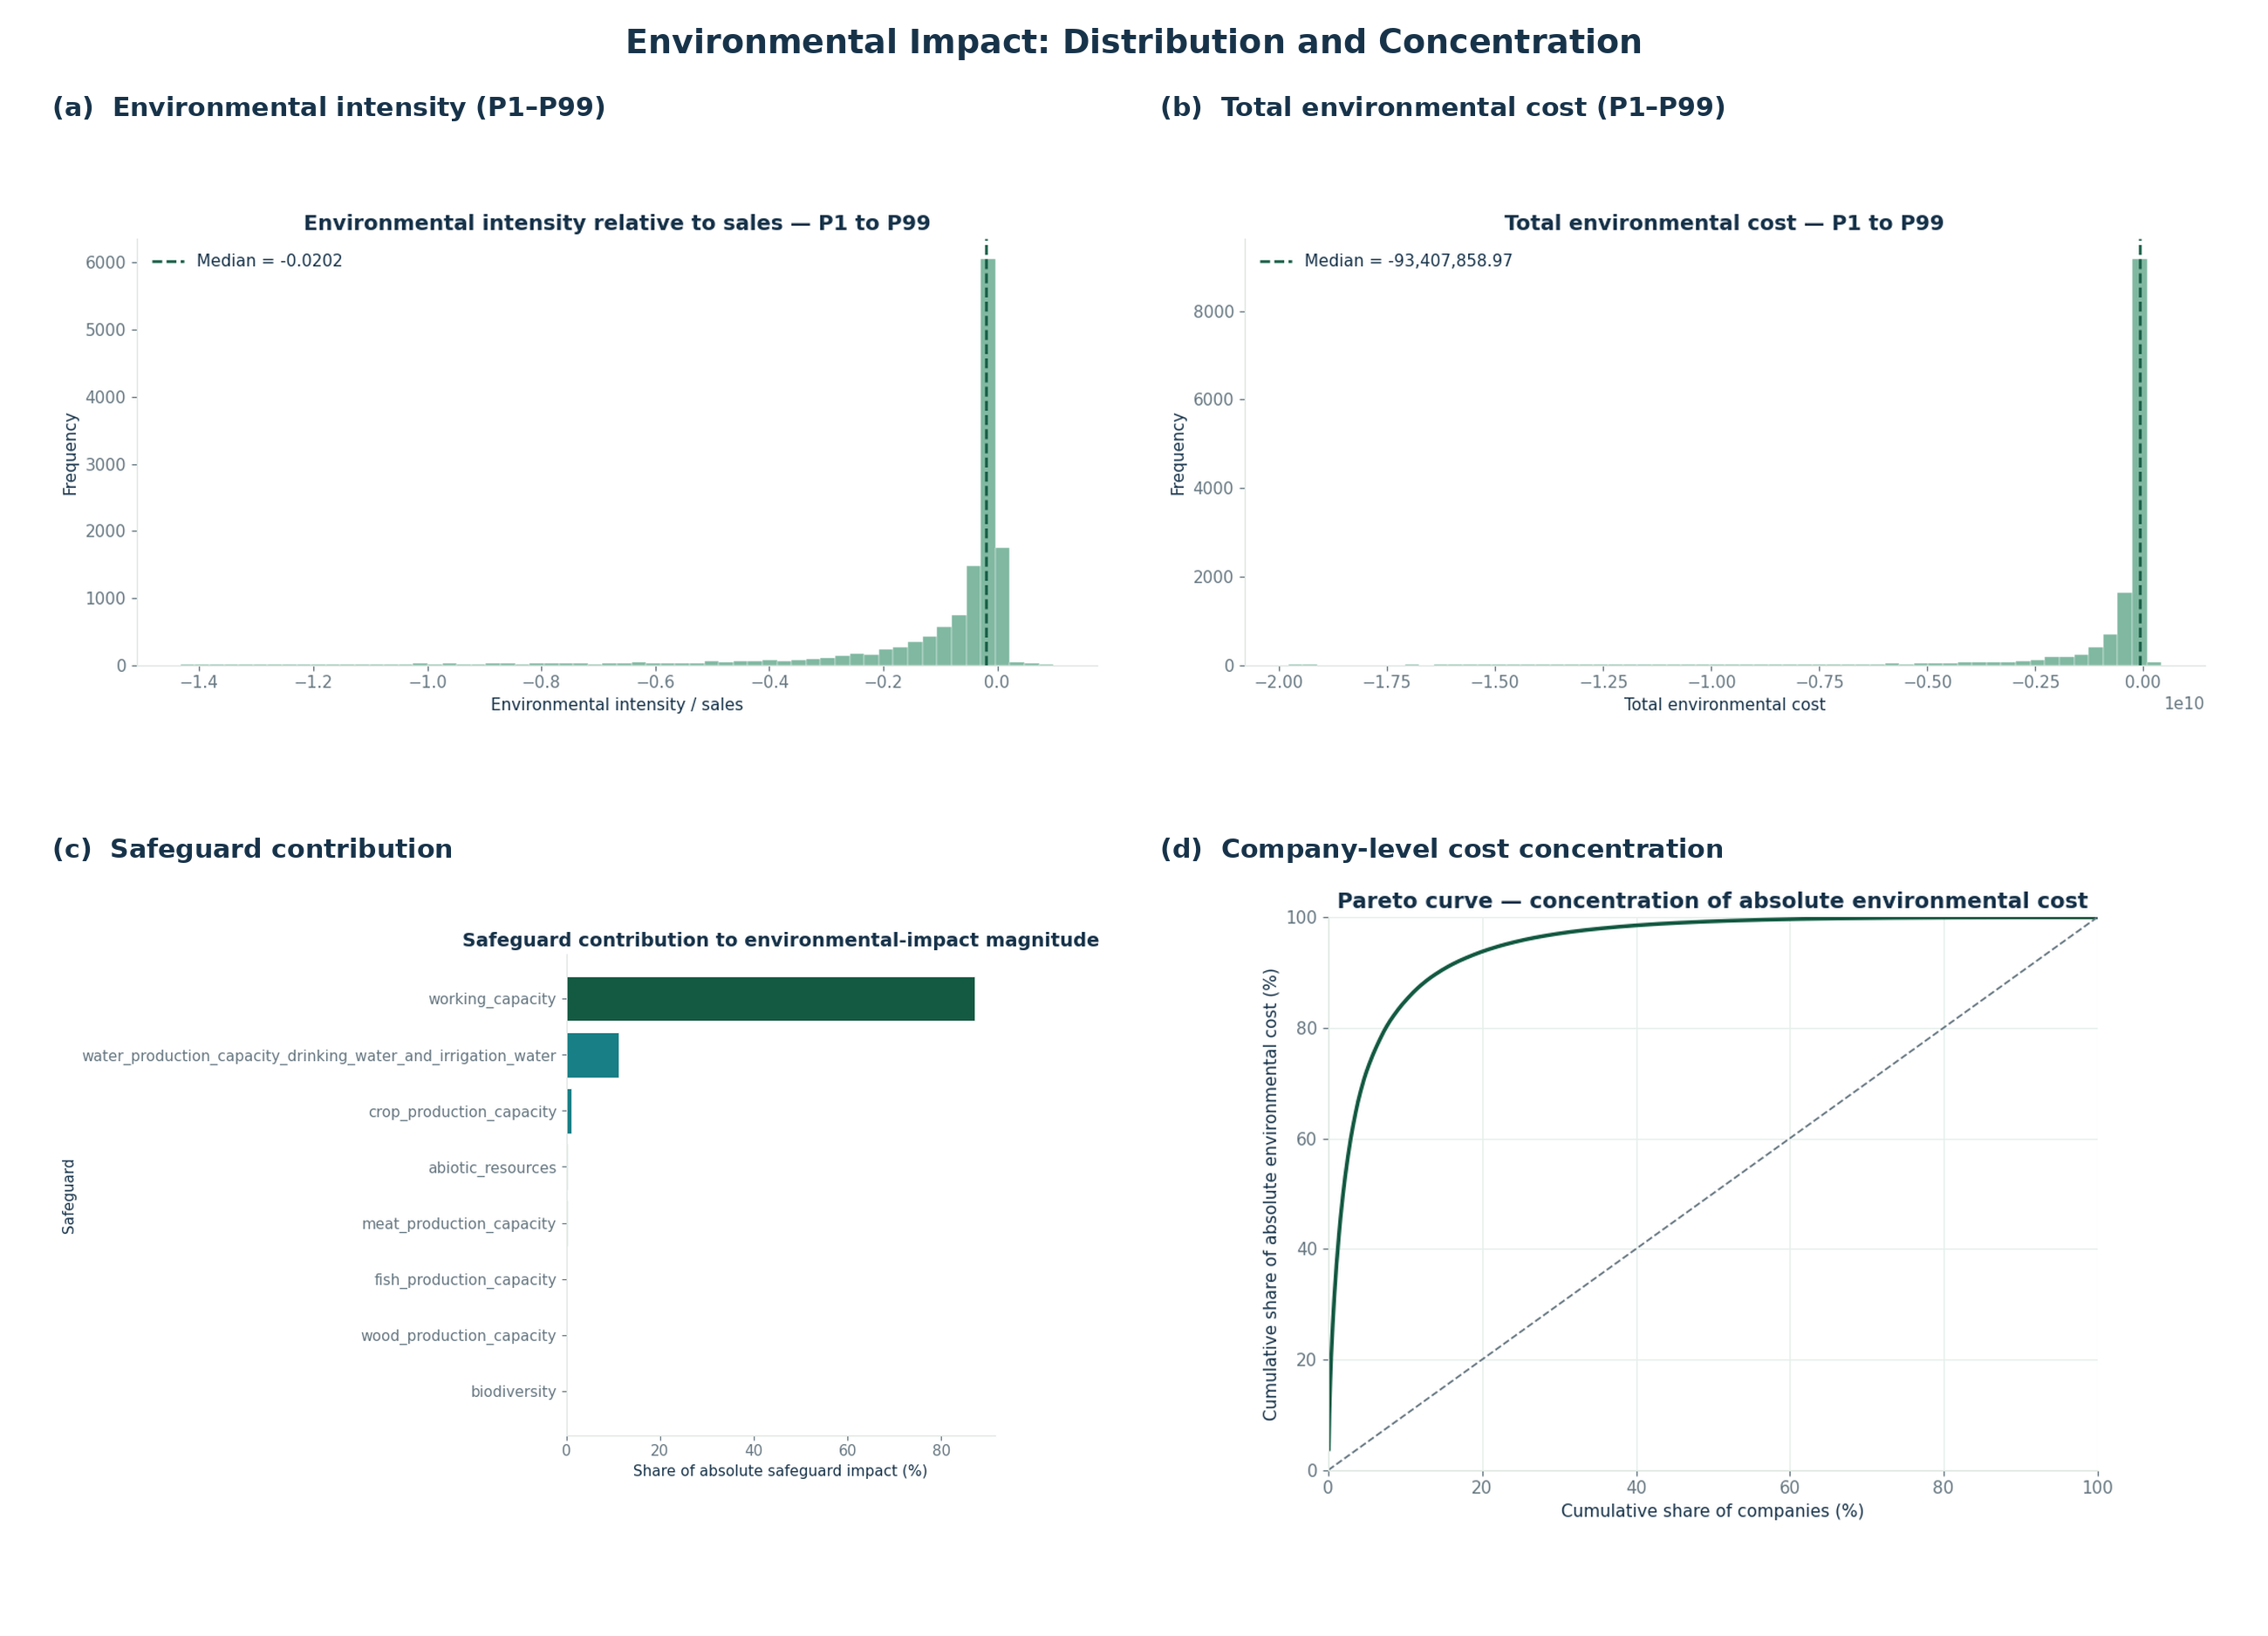

In [ ]:
# Publication-ready multi-panel Figure 1
# Panels: (a) environmental intensity, (b) total environmental cost,
# (c) safeguard contribution, and (d) company-level cost concentration.

fig, axes = plt.subplots(2, 2, figsize=(16, 10), dpi=180)
fig.suptitle(
    "Environmental impact: distribution and concentration",
    fontsize=18, fontweight="bold", color=COLORS["navy"], y=0.99
)

# (a) Environmental intensity, restricted to P1–P99 for display.
ax = axes[0, 0]
intensity = df[INTENSITY].dropna()
p1, p99 = intensity.quantile([0.01, 0.99])
intensity_display = intensity[(intensity >= p1) & (intensity <= p99)]
ax.hist(intensity_display, bins=60, color=COLORS["sage"],
        edgecolor="white", linewidth=0.3)
ax.axvline(intensity.median(), color=COLORS["forest"], linestyle="--",
           linewidth=1.8, label=f"Median = {intensity.median():.4f}")
ax.set_title("(a) Environmental intensity (P1–P99)", loc="left")
ax.set_xlabel("Environmental intensity / sales")
ax.set_ylabel("Frequency")
ax.legend(frameon=False)

# (b) Total environmental cost, restricted to P1–P99 for display.
ax = axes[0, 1]
cost = df[TOTAL_COST].dropna()
c1, c99 = cost.quantile([0.01, 0.99])
cost_display = cost[(cost >= c1) & (cost <= c99)]
ax.hist(cost_display, bins=60, color=COLORS["green"],
        edgecolor="white", linewidth=0.3)
ax.axvline(cost.median(), color=COLORS["forest"], linestyle="--",
           linewidth=1.8, label=f"Median = {cost.median():,.0f}")
ax.set_title("(b) Total environmental cost (P1–P99)", loc="left")
ax.set_xlabel("Total environmental cost")
ax.set_ylabel("Frequency")
ax.legend(frameon=False)

# (c) Absolute contribution of the eight safeguard dimensions.
ax = axes[1, 0]
safeguard_share = (
    df[SAFEGUARD_COLS].abs().sum()
    / df[SAFEGUARD_COLS].abs().sum().sum()
    * 100
).sort_values()
safeguard_names = {
    "working_capacity": "Working capacity",
    "fish_production_capacity": "Fish production",
    "crop_production_capacity": "Crop production",
    "meat_production_capacity": "Meat production",
    "biodiversity": "Biodiversity",
    "abiotic_resources": "Abiotic resources",
    "water_production_capacity_drinking_water_and_irrigation_water": "Water production",
    "wood_production_capacity": "Wood production",
}
labels = [safeguard_names.get(x, x) for x in safeguard_share.index]
bar_colors = [COLORS["mint"], COLORS["sage"], COLORS["sage"], COLORS["green"],
              COLORS["green"], COLORS["teal"], COLORS["teal"], COLORS["forest"]]
ax.barh(labels, safeguard_share.values, color=bar_colors[-len(labels):],
        edgecolor="white", linewidth=0.5)
ax.set_title("(c) Safeguard contribution", loc="left")
ax.set_xlabel("Share of absolute safeguard magnitude (%)")
ax.set_ylabel("")
ax.grid(axis="x", color=COLORS["grid"])
ax.set_axisbelow(True)

# (d) Company-level concentration of absolute environmental cost.
ax = axes[1, 1]
ax.plot(
    company_impact["cumulative_company_share"] * 100,
    company_impact["cumulative_cost_share"] * 100,
    color=COLORS["forest"], linewidth=2.5, label="Observed concentration"
)
ax.plot([0, 100], [0, 100], color=COLORS["gray"], linestyle="--",
        linewidth=1.2, label="Equal-share reference")
for pct in (1, 5, 10):
    n_top = max(1, int(np.ceil(len(company_impact) * pct / 100)))
    share = (
        company_impact.head(n_top)["total_absolute_environmental_cost"].sum()
        / company_impact["total_absolute_environmental_cost"].sum()
        * 100
    )
    x_pos = n_top / len(company_impact) * 100
    ax.scatter(x_pos, share, color=COLORS["teal"], s=35, zorder=4)
    ax.annotate(f"Top {pct}%: {share:.1f}%", (x_pos, share),
                xytext=(8, -12 if pct == 1 else 8),
                textcoords="offset points", fontsize=8, color=COLORS["navy"])
ax.set_title("(d) Company-level cost concentration", loc="left")
ax.set_xlabel("Cumulative share of companies (%)")
ax.set_ylabel("Cumulative share of absolute cost (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 105)
ax.legend(frameon=False, fontsize=8, loc="lower right")

for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=COLORS["grid"], alpha=0.8)
    ax.set_axisbelow(True)

fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig("EDA_Figure_1_Distribution_Concentration.png",
            dpi=300, bbox_inches="tight")
plt.show()


**Figure 1 | Environmental impact is highly skewed and concentrated across safeguard dimensions and companies.** (a) Distribution of environmental intensity relative to sales, restricted to the P1–P99 range for display. (b) Distribution of total environmental cost, restricted to P1–P99. (c) Contribution of the eight safeguard dimensions to total absolute safeguard magnitude. (d) Cumulative share of absolute environmental cost by company rank. The dataset contains 14,015 company-year observations from 2,485 companies across 68 countries during 2010–2019.

Both environmental-impact measures are concentrated near zero but exhibit pronounced negative tails, with the median environmental intensity at −0.0202. The composition analysis shows that Working Capacity (87.07%) and Water Production Capacity (11.13%) jointly account for 98.20% of total absolute safeguard magnitude. Environmental costs are also highly concentrated across companies: the top 1%, 5%, and 10% account for 36.37%, 72.40%, and 84.91% of aggregate absolute cost, respectively. These figures describe accumulated absolute costs across observed years rather than standardized annual company performance.

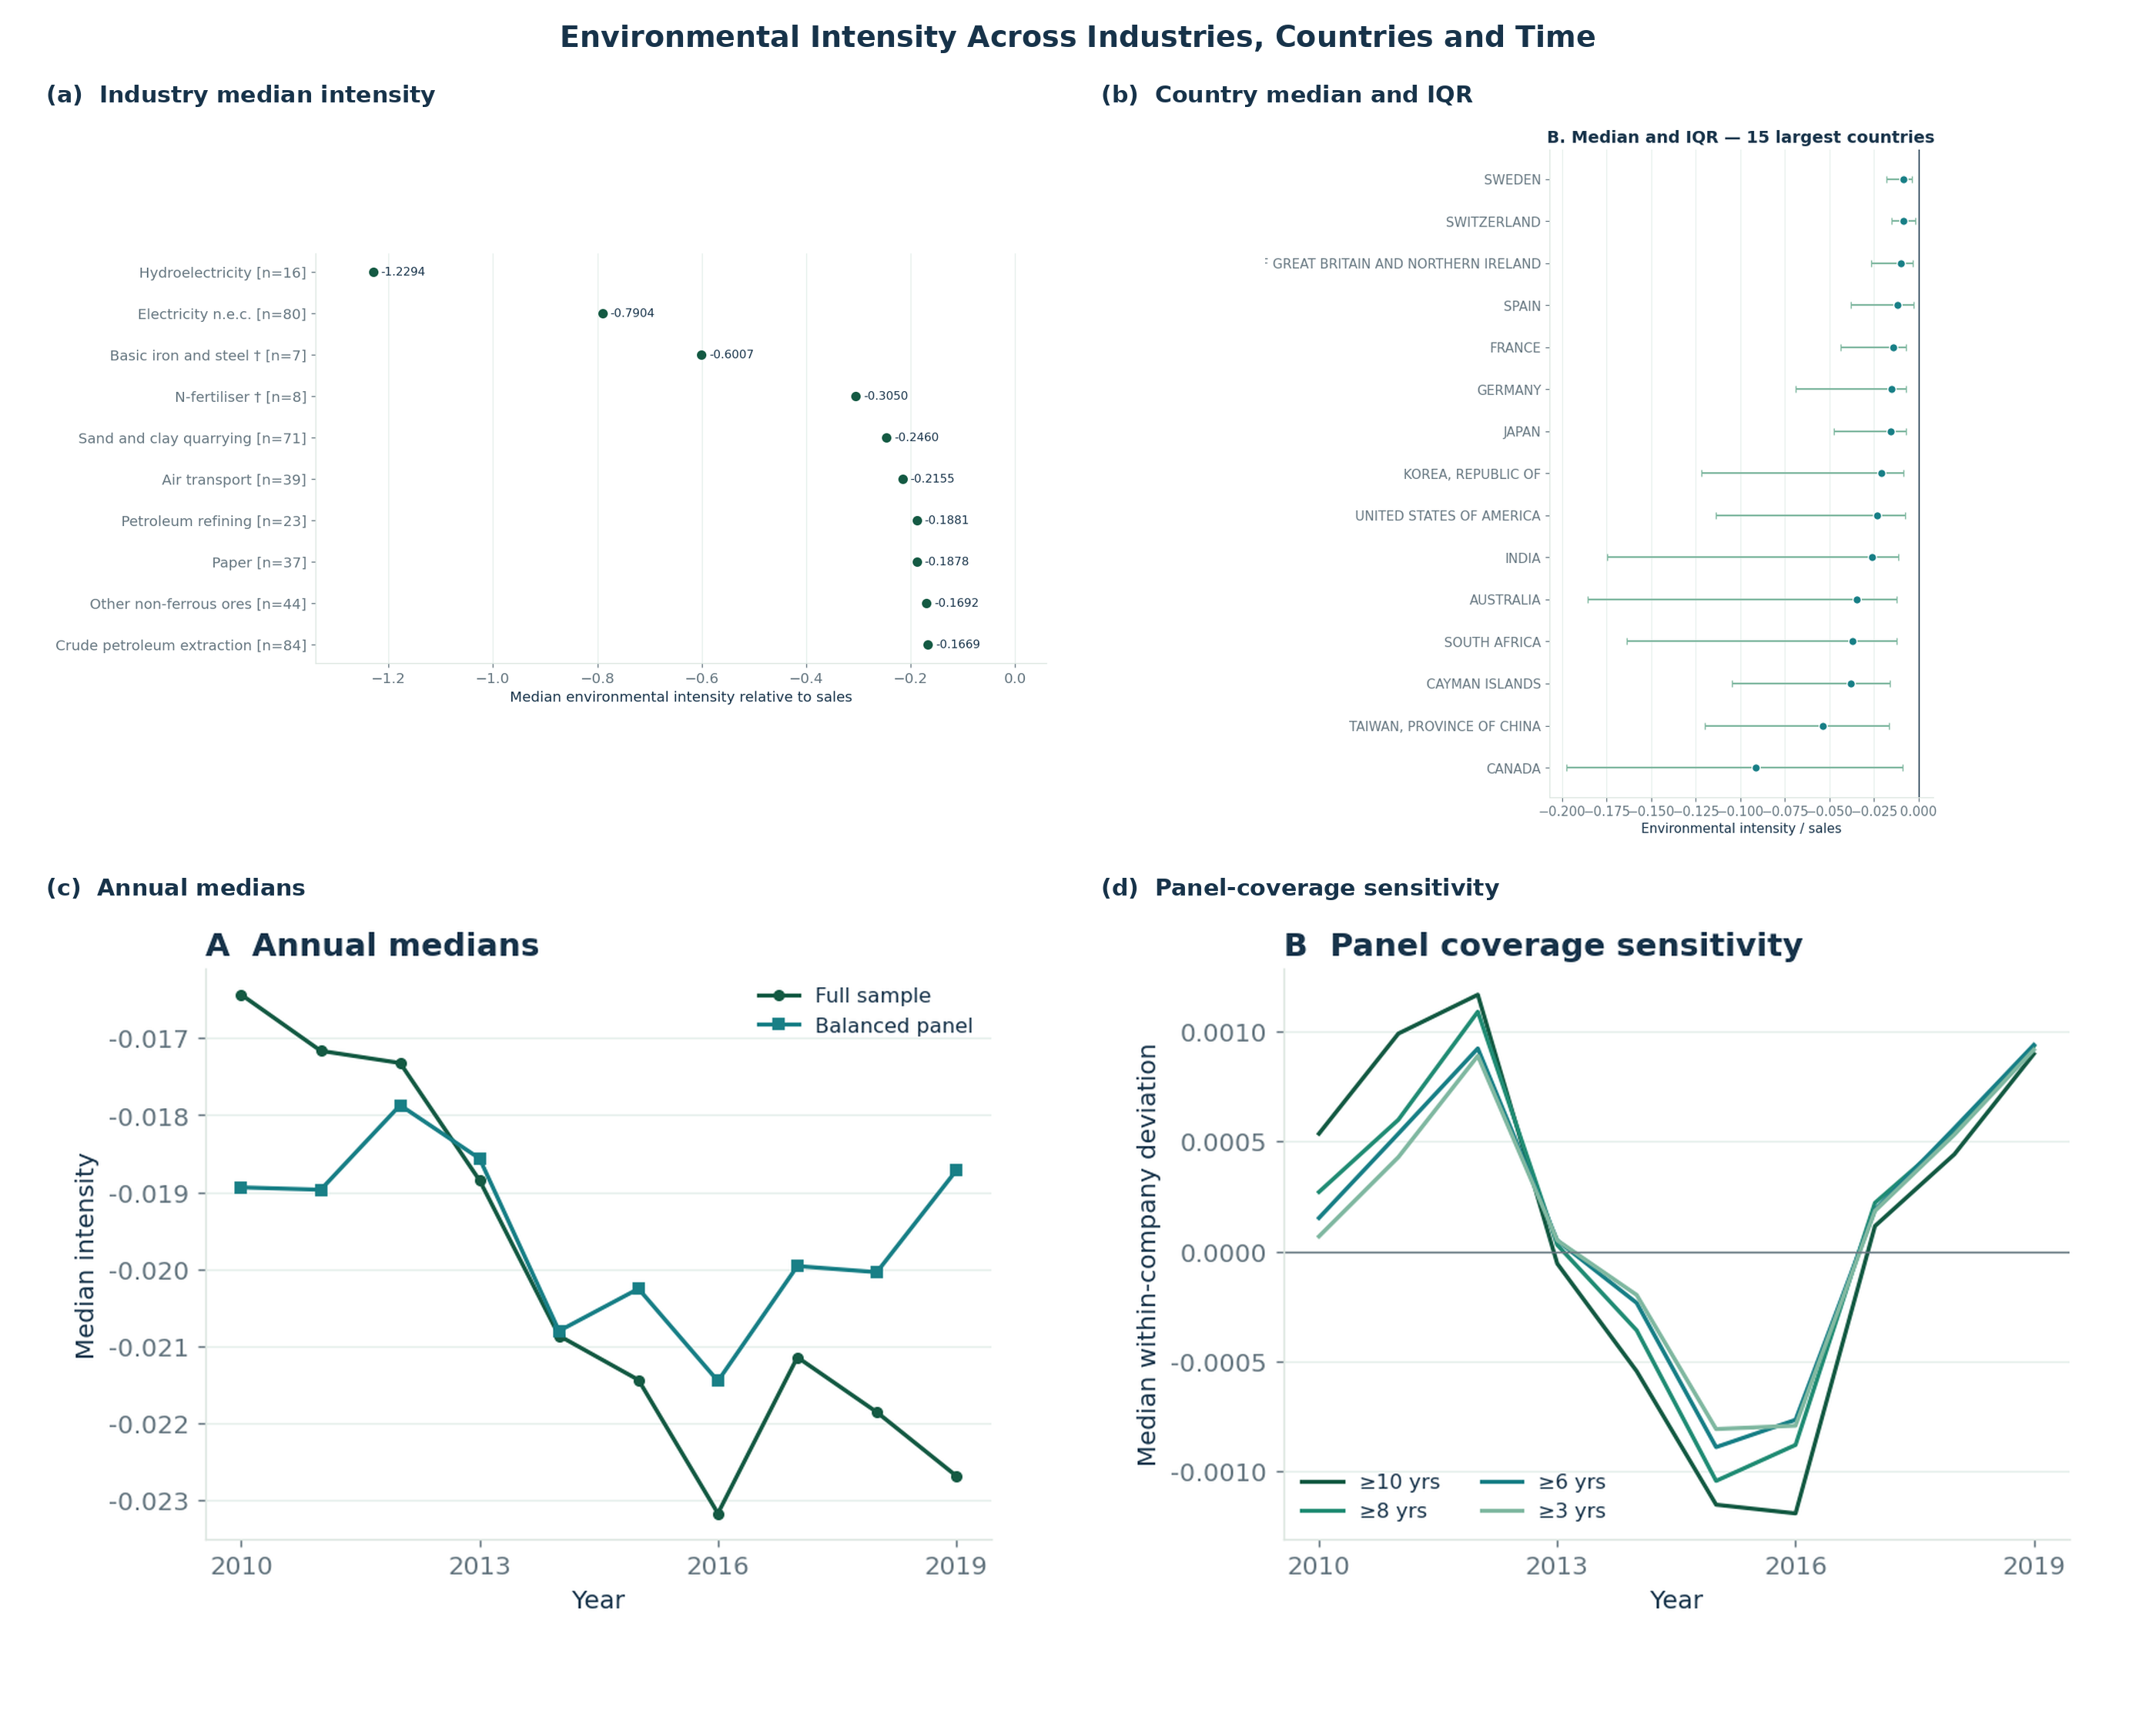

In [ ]:
# Publication-ready multi-panel Figure 2
# Panels: (a) industry medians, (b) country medians and IQR,
# (c) annual medians, and (d) sensitivity to panel-coverage requirements.

fig, axes = plt.subplots(2, 2, figsize=(17, 11), dpi=180)
fig.suptitle(
    "Environmental intensity across industries, countries and time",
    fontsize=18, fontweight="bold", color=COLORS["navy"], y=0.99
)

# (a) Ten most negative industry medians among groups with N >= 30.
ax = axes[0, 0]
industry_plot = (
    industry_summary.loc[industry_summary["N"] >= 30]
    .sort_values("Median")
    .head(10)
    .sort_values("Median", ascending=False)
)
industry_company_counts = df.groupby(INDUSTRY)[COMPANY].nunique()
industry_labels = [
    f"{textwrap.shorten(str(name), width=32, placeholder='…')} "
    f"[n={industry_company_counts.get(name, 0)}]"
    for name in industry_plot.index
]
y = np.arange(len(industry_plot))
ax.scatter(industry_plot["Median"], y, color=COLORS["forest"], s=38, zorder=3)
for yy, value in zip(y, industry_plot["Median"]):
    ax.annotate(f"{value:.4f}", (value, yy), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8)
ax.set_yticks(y, industry_labels)
ax.invert_yaxis()
ax.set_title("(a) Industry median intensity", loc="left")
ax.set_xlabel("Median environmental intensity / sales")
ax.set_ylabel("")
ax.grid(axis="x", color=COLORS["grid"])
ax.set_axisbelow(True)

# (b) Median and IQR for the 15 largest countries by observation count.
ax = axes[0, 1]
country_plot = (
    country_summary.sort_values("N", ascending=False)
    .head(15)
    .sort_values("Median")
)
y = np.arange(len(country_plot))
median = country_plot["Median"].to_numpy()
lower = median - country_plot["P25"].to_numpy()
upper = country_plot["P75"].to_numpy() - median
ax.errorbar(
    median, y, xerr=[lower, upper], fmt="o",
    color=COLORS["teal"], ecolor=COLORS["sage"],
    markeredgecolor="white", capsize=3, elinewidth=1.4, markersize=5
)
country_labels = [
    textwrap.shorten(str(name), width=25, placeholder="…")
    for name in country_plot.index
]
ax.set_yticks(y, country_labels)
ax.axvline(0, color=COLORS["navy"], linewidth=0.9)
ax.set_title("(b) Country median and IQR — 15 largest countries", loc="left")
ax.set_xlabel("Environmental intensity / sales")
ax.set_ylabel("")
ax.grid(axis="x", color=COLORS["grid"])
ax.set_axisbelow(True)

# (c) Annual median intensity: full sample versus balanced panel.
ax = axes[1, 0]
years = comparison.index.to_numpy()
ax.plot(
    years, comparison["Full sample median"],
    marker="o", color=COLORS["forest"], linewidth=2,
    label="Full sample"
)
ax.plot(
    years, comparison["Balanced panel median"],
    marker="s", color=COLORS["teal"], linewidth=2,
    label="Balanced panel"
)
ax.set_title("(c) Annual median environmental intensity", loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Median environmental intensity / sales")
ax.set_xticks(years)
ax.legend(frameon=False)
ax.grid(axis="y", color=COLORS["grid"])
ax.set_axisbelow(True)

# (d) Sensitivity of within-firm temporal patterns to panel coverage.
ax = axes[1, 1]
sensitivity_colors = [COLORS["forest"], COLORS["green"], COLORS["teal"], COLORS["sage"]]
for (column, color) in zip(panel_sensitivity.columns, sensitivity_colors):
    ax.plot(
        panel_sensitivity.index,
        panel_sensitivity[column] / 1000,
        linewidth=2, color=color, label=column
    )
ax.axhline(0, color=COLORS["gray"], linewidth=0.9)
ax.set_title("(d) Panel-coverage sensitivity", loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Median within-company deviation")
ax.set_xticks([2010, 2013, 2016, 2019])
ax.legend(frameon=False, fontsize=8, ncol=2)
ax.grid(axis="y", color=COLORS["grid"])
ax.set_axisbelow(True)

for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig("EDA_Figure_2_Industry_Country_Time.png",
            dpi=300, bbox_inches="tight")
plt.show()


**Figure 2 | Environmental intensity differs more strongly across industries than across countries or years.** (a) Ten most negative industry medians among industries with at least 30 firm-year observations. (b) Median and interquartile range for the 15 largest countries by observation count. (c) Annual median intensity in the full sample and the balanced panel. (d) Median within-company deviation under alternative minimum-observation requirements (at least 10, 8, 6, or 3 years). Statistical test results and effect sizes are reported in the comparison table above.

Industry differences show the largest rank-based effect (Kruskal–Wallis H = 6,264.01, η²H = 0.448), which remains large in the company-level robustness analysis (η²H = 0.431). Country differences are statistically significant but more moderate (η²H = 0.094). The full-sample median becomes more negative from −0.0164 in 2010 to −0.0227 in 2019, yet the year effect is negligible (η²H = 0.0017). The balanced panel of 498 companies reveals a non-linear mid-decade decline followed by recovery, and a similar pattern remains under less restrictive panel-coverage requirements. Overall, cross-sectional differences—particularly across industries—are more pronounced than temporal differences.